# Morocco Elections Analysis Toolkit — *Is power in the ballot box or with the Makhzen?*

**Version 3: five elections.** **Scope: 2002 → 2021, from the Jettou government to the Akhannouch government** (legislative elections of 2002, 2007, 2011, 2016 and 2021; governments Jettou, El Fassi, Benkirane I, El Othmani, Akhannouch).

This notebook turns three kinds of input into KPIs:

| Input | What it brings | Where it comes from |
|---|---|---|
| **Results** (votes by party × constituency) | competition, seat–vote distortion, forensics | TAFRA on openAfrica (2002, 2007, 2011, 2016, 2021) |
| **Population** (census by province) | registration, malapportionment, socio-economic profile | HCP: RGPH 2004 (for 2002 and 2007) and RGPH 2014 (for 2011, 2016 and 2021) |
| **Law** (seats, threshold, quotient base) | counterfactual simulation of the rules | Organic laws (encoded below) |

**How to use it**

1. Put the TAFRA results and the HCP census files listed in `PATHS` next to the notebook (the census files are downloaded if missing).
2. Run all cells. Everything ends up in one Excel file (`OUTPUT_XLSX`) and a set of PNG charts.

**What changed in version 3**

- Two more elections, 2002 and 2007 (325-seat chamber, 295 local seats).
- The survey module (Arab Barometer) is gone: no wave covers 2002 or 2007, so no survey metric is used anywhere.
- **2002 caveat.** The 2002 results file lists only nine parties; the votes of the smaller parties are not available. Every 2002 seat figure therefore over-allocates seats to those nine parties, and vote shares are shares of the listed votes only.

**Golden rule:** constituency- and province-level data describe places, not people. A correlation between illiteracy and a party's vote share does not mean illiterate people voted for that party (the ecological fallacy).


## KPI catalogue

Each KPI answers one of four tests: **Free** (can people compete and vote?), **Fair** (are the rules and administration neutral?), **Decisive** (does winning confer power?), and **Legitimacy** (do citizens take part?).

| # | KPI | Formula | Test | Reading |
|---|---|---|---|---|
| 1 | Parties winning seats | count | Free | more = more open competition |
| 2 | Effective number of parties, votes and seats (ENP) | $1/\sum p_i^2$ | Free / Decisive | high ENP_seats means a coalition is unavoidable |
| 3 | Winner's seat share | $s_{top}$ | Decisive | never above 1/3 points to a capped outcome |
| 4 | Minimum parties needed for a majority | parties summed in descending order until a majority of the chamber | Decisive | 3+ means the winner cannot govern without partners |
| 5 | Gallagher index | $\sqrt{\tfrac12\sum (v_i-s_i)^2}$ | Fair | seat–vote distortion |
| 6 | Seat bonus by party | $s_i - v_i$ | Fair | who the system rewards |
| 7 | **Engineering effect** | seats(actual rule) − seats(alternative rule) | Fair | how many seats the law itself moved, per party |
| 8 | Pedersen volatility | $\tfrac12\sum |p_{i,t}-p_{i,t-1}|$ | Free | voters really switching, not just reshuffling |
| 9 | Last-seat margin | votes of last elected list − best losing list (% of valid votes) | Free | small margins mean genuine local competition |
| 10 | Malapportionment (MAL) | $\tfrac12\sum |seat\_share - pop\_share|$ | Fair | unequal weight of votes between territories |
| 11 | Vote-weight ratio | max / min of population per seat | Fair | how much more one vote is worth in rural areas |
| 12 | Registration rate | registered / population aged 18+ | Legitimacy | who is even in the electorate |
| 13 | Real turnout | voters / population aged 18+ | Legitimacy | participation of the whole electorate |
| 14 | Turnout distribution (skew, share above 80%) | descriptive statistics | Integrity | spikes near 100% are red flags |
| 15 | Election fingerprint | corr(turnout, winner share) | Integrity | strong positive values can signal stuffing |
| 16 | Last-digit test | χ² against a uniform distribution | Integrity | weak signal; use only as a complement |
| 17 | Census correlations | ρ(urbanisation, illiteracy, unemployment ; turnout or party share) | Sociology | urban/rural cleavage, notables vs ideological vote |

The **Decisive** test also needs non-numeric facts (who was appointed, technocrat ministers, formation delay). Those live in the dashboard workbook, not here.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

ELECTIONS = ["2002", "2007", "2011", "2016", "2021"]
PATHS = {
    "results_2002": "parlement-elections-2002-1-0.xlsx",       # TAFRA, openAfrica (nine parties only)
    "results_2007": "parlement-elections-2007-1-0.xlsx",       # TAFRA, openAfrica
    "results_2011": "parlement-elections-2011-1-0.xlsx",       # TAFRA, openAfrica
    "results_2016": "parlement-elections-2016-1-1.xlsx",       # TAFRA, openAfrica
    "results_2021": "parlement-elections-2021-1-0.xlsx",       # TAFRA, openAfrica
    "boundaries":   "geoBoundaries-MAR-ADM2_simplified.geojson",   # province outlines (geoBoundaries / OpenStreetMap), downloaded if missing
    "census_2004":  "rgph2004_provinces.xlsx",             # built by fetch_hcp_census_2004() from applications-web.hcp.ma
    "census_2014":  "rgph2014_provinces.xlsx",             # built by fetch_hcp_census() from rgphentableaux.hcp.ma
}
CENSUS_FOR = {"2002": "2004", "2007": "2004", "2011": "2014", "2016": "2014", "2021": "2014"}   # census used for each election

# Map YOUR file's column names to the toolkit's standard names
COLUMN_MAP = {
    "results": {"circonscription": "circonscription", "province": "prefProv", "seats": "nSieges",
                "registered": "nInscrits", "turnout_rate": "txParticipation", "list_type": "typeListe"},
    "census":  {"province": "province", "population": "population", "pop18": "population_18_plus",
                "urban_rate": "taux_urbanisation", "illiteracy": "taux_analphabetisme",
                "unemployment": "taux_chomage"},
}
# Registered voters. TAFRA has them per constituency for 2002, 2007 and 2011; 2016 and 2021 are estimated. Two corrections:
#  1. REGISTERED_NATIONAL: official national totals (Interior Ministry); the estimates are rescaled to add up to them.
#  2. PATHS["registered"]: optional CSV with columns year, circonscription, registered (official figures per constituency).
#     When the file exists, its values replace the estimates for the constituencies it lists.
REGISTERED_NATIONAL = {"2016": 15_702_592, "2021": 17_509_127}
PATHS["registered"] = "registered_voters.csv"
OUTPUT_XLSX = "kpi_elections_maroc_v3.xlsx"


Matplotlib is building the font cache; this may take a moment.


## The law, encoded as parameters

These values come from the organic laws as documented by the CNDH, the press and the 2016 research pack. Scope: the three elections from Benkirane to Akhannouch.

`quota_basis` decides how the electoral quotient is computed:
- `"eligible_votes"`: valid votes of the lists that passed the threshold. **Verify the exact pre-2021 wording of LO 27.11, art. 84.**
- `"registered"`: registered voters (LO 04.21, 2021).

The chamber had 325 seats in 2002 and 2007 (295 local, 30 on a national list) and 395 from 2011. The 2002 and 2007 thresholds are marked *verify*: check them against the organic law of each election.


In [2]:
RULES = pd.DataFrame([
 # year, total, local, national, threshold, quota_basis, note, status
 ("2002",325,295,30,0.03,"eligible_votes","Proportional lists replace single-member seats; national list of 30 women; 3% threshold","verify"),
 ("2007",325,295,30,0.06,"eligible_votes","Local threshold raised to 6%","verify"),
 ("2011",395,305,90,0.06,"eligible_votes","LO 27.11: national list of 60 women + 30 youth","ok"),
 ("2016",395,305,90,0.03,"eligible_votes","LO 20.16: threshold 6%->3% (art. 84); youth list open to both sexes","ok"),
 ("2021",395,305,90,0.00,"registered","LO 04.21: quotient on registered voters, threshold removed, regional lists","ok"),
], columns=["year","total_seats","local_seats","national_seats","threshold","quota_basis","note","status"]).set_index("year")
RULES["majority"] = RULES.total_seats // 2 + 1
RULES


,total_seats,local_seats,national_seats,threshold,quota_basis,note,status,majority
year,,,,,,,,
2002,325,295,30,0.03,eligible_votes,Proportional lists replace single-member seats...,verify,163
2007,325,295,30,0.06,eligible_votes,Local threshold raised to 6%,verify,163
2011,395,305,90,0.06,eligible_votes,LO 27.11: national list of 60 women + 30 youth,ok,198
2016,395,305,90,0.03,eligible_votes,LO 20.16: threshold 6%->3% (art. 84); youth li...,ok,198
2021,395,305,90,0.00,registered,"LO 04.21: quotient on registered voters, thres...",ok,198


## Core tools

In [3]:
def allocate_seats(votes, seats, threshold=0.0, quota_basis="eligible_votes", registered=None):
    # Largest-remainder PR for one constituency. votes: pd.Series(party -> votes).
    votes = votes.fillna(0).astype(float)
    valid = votes.sum()
    eligible = votes[votes >= threshold * valid] if threshold > 0 else votes[votes > 0]
    if eligible.empty or seats <= 0:
        return pd.Series(0, index=votes.index, dtype=int)
    base = {"eligible_votes": eligible.sum(), "valid_votes": valid,
            "registered": registered if registered else valid}[quota_basis]
    quota = base / seats
    full = np.floor(eligible / quota).astype(int)
    if full.sum() > seats:                      # safety net (should not happen)
        full = (full * seats // full.sum()).astype(int)
    remaining = seats - full.sum()
    rema = (eligible - full * quota).sort_values(ascending=False)
    for p in rema.index[:remaining]:
        full[p] += 1
    out = pd.Series(0, index=votes.index, dtype=int); out[full.index] = full
    return out

def enp(shares):
    s = np.asarray(shares, float); s = s[s > 0]; s = s / s.sum()
    return 1 / np.sum(s ** 2)

def gallagher(v, s):
    v, s = np.asarray(v, float), np.asarray(s, float)
    v, s = v / v.sum(), s / s.sum()
    return np.sqrt(0.5 * np.sum((v - s) ** 2)) * 100

def pedersen(p_t, p_prev):
    a = pd.concat([p_t / p_t.sum(), p_prev / p_prev.sum()], axis=1).fillna(0)
    return 0.5 * (a.iloc[:, 0] - a.iloc[:, 1]).abs().sum() * 100

def min_parties_for_majority(seat_series, majority):
    c = seat_series.sort_values(ascending=False).cumsum()
    return int((c < majority).sum() + 1) if c.iloc[-1] >= majority else np.nan

def malapportionment(seats, population):
    s, p = np.asarray(seats, float), np.asarray(population, float)
    return 0.5 * np.abs(s / s.sum() - p / p.sum()).sum() * 100

## HCP census (RGPH 2014) by province

The HCP table generator ([rgphentableaux.hcp.ma](http://rgphentableaux.hcp.ma/)) shows one province at a time and has no bulk export. `fetch_hcp_census()` asks it for each of the 75 provinces and prefectures (themes *Démographie*, *Education et alphabétisation*, *Activité et emploi*) and saves one row per province:

| Column in the file | HCP indicator | Note |
|---|---|---|
| `population` | Population municipale (ensemble) | |
| `population_18_plus` | Répartition selon le groupe d'âges quinquennal | estimate: ages 20+ plus 2/5 of the 15–19 group |
| `taux_urbanisation` | Population municipale, urbain ÷ ensemble | 0–1 |
| `taux_analphabetisme` | Taux d'analphabétisme | population aged 10+, 0–1 |
| `taux_chomage` | Taux de chômage | 0–1 |

The download runs only when the file in `PATHS["census_2014"]` does not exist yet (about 230 small requests, 2–3 minutes).

In [4]:
HCP_URL = "http://rgphentableaux.hcp.ma/Default1/"

def fetch_hcp_census(out_path, pause=0.2):
    # Downloads RGPH 2014 indicators for every province/prefecture from the HCP table generator
    # (one province per request: themes 2 = demography, 4 = education, 6 = activity) and saves one row per province.
    import requests, re, html, time
    head = {"User-Agent": "Mozilla/5.0", "X-Requested-With": "XMLHttpRequest", "Referer": HCP_URL}
    page = requests.get(HCP_URL, headers=head, timeout=60).text
    block = re.search(r'id="PROVINCESLIST".*?</select>', page, re.S).group(0)
    provinces = [(c.strip(), html.unescape(n).strip()) for c, n in re.findall(r'<option[^>]*value="([^"]+)"[^>]*>(.*?)</option>', block, re.S)]
    rows = []
    for code, name in provinces:
        ind = {}
        for theme in (2, 4, 6):
            r = requests.get(HCP_URL + "getDATA/", params={"type": "Province", "CGEO": code, "them": theme}, headers=head, timeout=60)
            ind.update({d["INDICATEUR"]: pd.to_numeric(d["DATA2014"], errors="coerce") for d in r.json()})
            time.sleep(pause)
        if "IEE_Population municipale" not in ind or pd.isna(ind["IEE_Population municipale"]): continue   # placeholder entry in the list
        age = "IEE_Répartition selon le groupe d'âges quinquennal_"       # IEE = both sexes, urban + rural; IUE = urban
        share18 = (0.4 * ind[age + "15-19 ans"] + sum(v for k, v in ind.items() if k.startswith(age) and int(re.search(r"_(\d+)", k).group(1)) >= 20)) / 100
        pop = ind["IEE_Population municipale"]
        urban = ind.get("IUE_Population municipale", 0)
        rows.append({"code_hcp": code, "province": name, "population": int(pop),
                     "population_18_plus": int(round(pop * share18)),          # estimate: 20+ and 2/5 of the 15-19 group
                     "taux_urbanisation": round((0 if pd.isna(urban) else urban) / pop, 4),
                     "taux_analphabetisme": ind["IEE_Taux d'analphabétisme"] / 100,   # population aged 10+
                     "taux_chomage": ind["IEE_Taux de chômage"] / 100})
    census = pd.DataFrame(rows)
    census.to_excel(out_path, index=False)
    return census

import os
if not os.path.exists(PATHS["census_2014"]):
    fetch_hcp_census(PATHS["census_2014"])


## HCP census (RGPH 2004) by province

The 2002 and 2007 elections use the 2004 census, read from the HCP application *Le Maroc en chiffres* ([applications-web.hcp.ma/hpmc](https://applications-web.hcp.ma/hpmc/frmmarocenchiffres.aspx)). `fetch_hcp_census_2004()` selects each province in turn and reads three profiles, plus the population of every urban unit of the province:

| Column in the file | Source in the application | Note |
|---|---|---|
| `population` | Population totale | |
| `population_18_plus` | 18 ans et plus | exact count |
| `taux_urbanisation` | population of municipalities (MU), arrondissements (AR) and urban centres (AC) ÷ total | 0–1 |
| `taux_analphabetisme` | Langues parlées et écrites: *Aucune*, population aged 10+ | 0–1 |
| `taux_chomage` | 1 − (employed + unemployed who have worked before) ÷ active population | **proxy**: the application gives no unemployment rate, so this is the share of first-time job seekers among the active population |

The download runs only when the file in `PATHS["census_2004"]` is missing (about 650 requests, 10 minutes).

In [5]:
HCP_2004_URL = "https://applications-web.hcp.ma/hpmc/frmmarocenchiffres.aspx"

def fetch_hcp_census_2004(out_path, pause=0.05):
    # ASP.NET form: each selection is a postback carrying the hidden state of the previous page.
    import requests, re, html, time
    s = requests.Session(); s.headers["User-Agent"] = "Mozilla/5.0"
    N = r"((?:\d{1,3} )*\d{1,3})"
    num = lambda x: int(x.replace(" ", ""))
    def options(t, name):
        m = re.search(r'<select[^>]*name="%s".*?</select>' % name, t, re.S)
        return [(v, html.unescape(n).strip()) for v, n in re.findall(r'<option[^>]*value="([^"]*)"[^>]*>(.*?)</option>', m.group(0), re.S)] if m else []
    def text(t):
        b = re.sub(r"<script.*?</script>|<style.*?</style>|<select.*?</select>", "", t, flags=re.S)
        return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", b)))
    def post(t, target, **fields):
        d = {m.group(1): html.unescape(m.group(2)) for m in re.finditer(r'<input type="hidden" name="([^"]+)"[^>]*value="([^"]*)"', t)}
        d["__EVENTTARGET"], d["__EVENTARGUMENT"] = target, ""
        for n in ("lRE", "lPR", "lCMA"):
            m = re.search(r'<select[^>]*name="%s".*?</select>' % n, t, re.S)
            sel = m and re.search(r'<option selected="selected" value="([^"]*)"', m.group(0))
            if sel: d[n] = sel.group(1)
        tp = re.search(r'name="typeProfil" value="(\w)" checked', t); d["typeProfil"] = tp.group(1) if tp else "d"
        d.update(fields); r = s.post(HCP_2004_URL, data=d, timeout=60); r.encoding = "utf-8"; return r.text
    pop = lambda tx: num(re.search(r"Population totale " + N + " 100", tx).group(1))
    home, rows = s.get(HCP_2004_URL, timeout=60).text, []
    for rv, rn in options(home, "lRE")[1:]:
        reg = post(home, "lRE", lRE=rv)
        for pv, pn in options(reg, "lPR")[1:]:
            t = post(reg, "lPR", lPR=pv); d = text(t)
            soc = text(post(t, "typeProfil$1", typeProfil="s")); eco = text(post(t, "typeProfil$2", typeProfil="e"))
            lit = re.search(r"LANGUES PARLEES ET ECRITES Population 10 ans et plus " + N + " 100 Aucune " + N + r" \d{1,3}(?:,\d+)? F", soc)
            act = re.search(r"Actifs " + N + r" \d{1,3}(?:,\d+)? F.*?Actifs occupés et chômeurs ayant déjà travaillés " + N + " 100", eco)
            urban = 0
            for cv, cn in options(t, "lCMA")[1:]:
                if cn.split("-")[0].strip().upper() in ("MU", "AR", "AC"):
                    urban += pop(text(post(t, "lCMA", lCMA=cv))); time.sleep(pause)
            rows.append({"code_hcp": pv, "province": pn, "population": pop(d),
                         "population_18_plus": num(re.search(r"18 ans et plus " + N + r" \d{1,3}(?:,\d+)? F", d).group(1)),
                         "taux_urbanisation": round(urban / pop(d), 4),
                         "taux_analphabetisme": round(num(lit.group(2)) / num(lit.group(1)), 4),
                         "taux_chomage": round(1 - num(act.group(2)) / num(act.group(1)), 4)})   # proxy, see the table above
    census = pd.DataFrame(rows)
    census["province"] = census["province"].replace({"Chouka Ait Baha": "Chtouka Ait Baha", "El Kelaa Sraghna": "El Kelaa des Sraghna",
                                                     "Ouajda Angad": "Oujda Angad", "Mohammedia": "Mohammadia"})   # spelling slips in the source
    census.to_excel(out_path, index=False)
    return census

if not os.path.exists(PATHS["census_2004"]):
    fetch_hcp_census_2004(PATHS["census_2004"])


## Loading data


In [6]:
import os
def load_tafra(path, year, cmap=COLUMN_MAP["results"]):
    # Reads a wide TAFRA sheet (one row per constituency and list type, one column per party) -> long standard format.
    raw = pd.read_excel(path, sheet_name=0)
    raw = raw.rename(columns={v: k for k, v in cmap.items() if v in raw.columns})
    if "list_type" in raw: raw = raw[raw["list_type"] == "locale"]          # national / regional lists are not modelled
    not_party = {"region", "wilaya", "sousPref", "pctNuls", "invalide", *cmap}  # + ids (id*) and winners' profile (rep*)
    party_cols = [c for c in raw.columns if c not in not_party and not c.startswith(("id", "rep"))
                  and pd.api.types.is_numeric_dtype(raw[c])]
    valid = raw[party_cols].sum(axis=1)
    # TAFRA gives registered voters for 2011 only. Elsewhere: valid votes / turnout rate (too low, spoiled ballots are
    # not reported), rescaled to the official national total, then replaced by official constituency figures if supplied.
    est = raw["registered"].isna()
    raw.loc[est, "registered"] = (valid / raw["turnout_rate"])[est]
    raw["registered_source"] = np.where(est, "estimated (lower bound)", "TAFRA")
    if est.any() and REGISTERED_NATIONAL.get(year):
        raw.loc[est, "registered"] *= (REGISTERED_NATIONAL[year] - raw.loc[~est, "registered"].sum()) / raw.loc[est, "registered"].sum()
        raw.loc[est, "registered_source"] = "estimated, scaled to national total"
    if os.path.exists(PATHS.get("registered", "")):
        off = pd.read_csv(PATHS["registered"], dtype={"year": str})
        off = off[off["year"] == year].set_index("circonscription")["registered"]
        hit = raw["circonscription"].isin(off.index)
        raw.loc[hit, "registered"] = raw.loc[hit, "circonscription"].map(off)
        raw.loc[hit, "registered_source"] = "official (constituency)"
    raw["registered_estimated"] = raw["registered_source"].str.startswith("estimated")
    raw["registered"] = raw["registered"].round()
    raw["voters"] = (raw["registered"] * raw["turnout_rate"]).round()
    ids = ["circonscription", "province", "seats", "registered", "voters", "registered_estimated", "registered_source"]
    long = raw.melt(id_vars=ids, value_vars=party_cols, var_name="party", value_name="votes")
    long["votes"] = long["votes"].fillna(0)
    long["year"] = year
    return long

def province_key(name):
    # 'Chtouka - Aït-Baha' (TAFRA) and 'Chtouka Ait Baha' (HCP) -> 'chtoukaaitbaha', so the two spellings match
    import unicodedata, re
    return re.sub(r"[^a-z]", "", unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode().lower())

def load_census(path, cmap=COLUMN_MAP["census"]):
    raw = pd.read_excel(path)
    return raw.rename(columns={v: k for k, v in cmap.items() if v in raw.columns})

# Prefectures of the 2002 and 2007 results that the 2004 census reports under another province (keys from province_key)
OLD_PREFECTURES = {
 "alfidamerssultan": "casablanca",
 "ainchockhayhassani": "casablanca",
 "ainsebaahaymohammadi": "casablanca",
 "benmsickmediouana": "casablanca",
 "casablancaanfa": "casablanca",
 "moulayrachidsidiothmane": "casablanca",
 "sidibernoussizenata": "casablanca",
 "alismailia": "meknes",
 "mekneselmenzah": "meknes",
 "fahsbnimakada": "tangerassilah",
 "feseljadiddardbibagh": "fes",
 "fesmedina": "fes",
 "zouaghamoulayyacoub": "moulayyacoub",
 "marrakechmedina": "marrakech",
 "marrakechmenara": "marrakech",
 "sidiyoussefbenali": "marrakech",
 "salealjadida": "sale",
 "salemedina": "sale",
 "mdiqfnideq": "tetouan"
}

results = pd.concat([load_tafra(PATHS[f"results_{y}"], y) for y in ELECTIONS])
CENSUS = {c: load_census(PATHS[f"census_{c}"]) for c in sorted(set(CENSUS_FOR.values()))}
census_of = lambda year: CENSUS[CENSUS_FOR[year]]           # the census table used for one election
census = CENSUS["2014"]

def harmonise(prov, year):
    # give the results the census spelling of each province so the two tables merge
    names = dict(zip(census_of(year)["province"].map(province_key), census_of(year)["province"]))
    k = province_key(prov)
    if CENSUS_FOR[year] == "2004": k = OLD_PREFECTURES.get(k, k)
    return names.get(k, prov)

results["province"] = [harmonise(p, y) for p, y in zip(results["province"], results["year"])]
_miss = {y: sorted(set(results[results.year == y].province) - set(census_of(y).province)) for y in ELECTIONS}
print("Provinces without a census match:", {y: m for y, m in _miss.items() if m} or "none")
results.groupby("year").agg(constituencies=("circonscription", "nunique"), parties=("party", "nunique"), votes=("votes", "sum")).join(
    results.drop_duplicates(["year", "circonscription"]).groupby("year").agg(local_seats=("seats", "sum"), registered=("registered", "sum")))


Provinces without a census match: none


,constituencies,parties,votes,local_seats,registered
year,,,,,
2002,91,9,4142326.0,295.0,14023604.0
2007,95,38,4617381.0,295.0,15462362.0
2011,92,19,4745480.0,305.0,13420631.0
2016,92,28,5775030.0,305.0,15702587.0
2021,92,30,7588505.0,305.0,17509129.0


## 1 · National KPIs per election (Free · Decisive · Fair)

In [7]:
def simulate(res_year, threshold, quota_basis):
    out = []
    for c, g in res_year.groupby("circonscription"):
        v = g.set_index("party")["votes"]
        s = allocate_seats(v, int(g["seats"].iloc[0]), threshold, quota_basis, g["registered"].iloc[0])
        out.append(s.rename(c))
    return pd.concat(out, axis=1).fillna(0).sum(axis=1).astype(int)

def national_kpis(results, rules=RULES):
    rows, seat_tables = [], {}
    for y, g in results.groupby("year"):
        r = rules.loc[y]
        seats = simulate(g, r.threshold, r.quota_basis)
        votes = g.groupby("party")["votes"].sum()
        seat_tables[y] = pd.DataFrame({"votes": votes, "seats_local": seats})
        top = seats.idxmax()
        scaled = seats * r.total_seats / seats.sum()    # local seats scaled to the whole chamber (national lists not modelled)
        rows.append({"year": y, "parties_with_seats": int((seats > 0).sum()),
                     "ENP_votes": round(enp(votes), 2), "ENP_seats": round(enp(seats), 2),
                     "winner": top, "winner_seat_share": round(seats[top] / seats.sum(), 3),
                     "min_parties_majority": min_parties_for_majority(scaled, r.majority),
                     "gallagher": round(gallagher(votes.reindex(seats.index), seats), 2),
                     "turnout_registered": round(g.drop_duplicates("circonscription")["voters"].sum()
                                                 / g.drop_duplicates("circonscription")["registered"].sum(), 3)})
    k = pd.DataFrame(rows).set_index("year")
    ys = sorted(seat_tables)
    k["pedersen_volatility"] = [np.nan] + [round(pedersen(seat_tables[ys[i]]["votes"], seat_tables[ys[i-1]]["votes"]), 1) for i in range(1, len(ys))]
    return k, seat_tables

KPI_NATIONAL, SEATS = national_kpis(results)
KPI_NATIONAL

,parties_with_seats,ENP_votes,ENP_seats,winner,winner_seat_share,min_parties_majority,gallagher,turnout_registered,pedersen_volatility
year,,,,,,,,,
2002,9,7.38,6.67,MP,0.200,3,3.33,0.431,NaN
2007,24,15.15,10.17,PI,0.156,4,5.68,0.369,36.2
2011,14,8.82,6.46,PJD,0.275,3,5.86,0.455,31.9
2016,12,6.53,4.88,PJD,0.321,2,6.03,0.424,18.7
2021,10,6.32,4.92,RNI,0.282,2,6.44,0.514,30.2


## 2 · Engineering effect: what did the law change?

The same votes are re-run under every rule regime. Positive numbers mean the party gains seats under that rule compared with the rule actually in force. This is the most direct numerical test of "the rules shape the winner".

In [8]:
REGIMES = {"6% · eligible votes (2007, 2011)": (0.06, "eligible_votes"),
           "3% · eligible votes (2002, 2016)":      (0.03, "eligible_votes"),
           "0% · registered voters (2021)":  (0.00, "registered"),
           "0% · valid votes (pure PR)":      (0.00, "valid_votes")}

def engineering_effect(results, year):
    g = results[results.year == year]
    sim = pd.DataFrame({k: simulate(g, *v) for k, v in REGIMES.items()})
    actual = simulate(g, RULES.loc[year].threshold, RULES.loc[year].quota_basis)
    return sim.sub(actual, axis=0), sim

ENG = {}
for y in sorted(results.year.unique()):
    delta, sim = engineering_effect(results, y)
    ENG[y] = sim
    print(f"\n=== {y}: seats (local lists) under each rule ===")
    display(sim.sort_values(sim.columns[1], ascending=False))
    print("Difference vs the rule in force:")
    display(delta.loc[(delta != 0).any(axis=1)])


=== 2002: seats (local lists) under each rule ===


,"6% · eligible votes (2007, 2011)","3% · eligible votes (2002, 2016)",0% · registered voters (2021),0% · valid votes (pure PR)
party,,,,
MP,59,59,59,59
USFP,54,52,50,52
PI,48,47,47,47
PJD,46,45,39,45
RNI,41,43,46,43
UC,18,19,21,19
PND,16,17,19,17
PPS,11,11,12,11
PSU,2,2,2,2


Difference vs the rule in force:


,"6% · eligible votes (2007, 2011)","3% · eligible votes (2002, 2016)",0% · registered voters (2021),0% · valid votes (pure PR)
party,,,,
PI,1,0,0,0
PJD,1,0,-6,0
PND,-1,0,2,0
PPS,0,0,1,0
RNI,-2,0,3,0
UC,-1,0,2,0
USFP,2,0,-2,0



=== 2007: seats (local lists) under each rule ===


,"6% · eligible votes (2007, 2011)","3% · eligible votes (2002, 2016)",0% · registered voters (2021),0% · valid votes (pure PR)
party,,,,
PI,46,46,44,46
PJD,40,38,35,36
MP,36,36,38,37
RNI,34,34,35,34
USFP,33,33,34,33
UC,27,27,30,29
PPS,14,14,14,14
FFD,9,10,10,10
MDS,9,9,9,9


... (10 outputs left out)


=== 2021: seats (local lists) under each rule ===


,"6% · eligible votes (2007, 2011)","3% · eligible votes (2002, 2016)",0% · registered voters (2021),0% · valid votes (pure PR)
party,,,,
RNI,97,94,86,92
PAM,77,78,75,78
PI,67,68,68,69
USFP,21,21,23,21
MP,17,17,20,18
UC,12,12,13,12
PPS,9,10,12,10
MDS,3,3,3,3
FFD,1,1,1,1


Difference vs the rule in force:


,"6% · eligible votes (2007, 2011)","3% · eligible votes (2002, 2016)",0% · registered voters (2021),0% · valid votes (pure PR)
party,,,,
MP,-3,-3,0,-2
PAM,2,3,0,3
PI,-1,0,0,1
PJD,-3,-3,0,-3
PPS,-3,-2,0,-2
RNI,11,8,0,6
UC,-1,-1,0,-1
USFP,-2,-2,0,-2


### Same votes, different parliament

One election's votes counted under two rules: the 2016 rule (3% threshold, quotient on votes) and the 2021 rule (no threshold, quotient on registered voters). `SAME_VOTES` holds the seats under each rule and the difference; change `SV_YEAR` to use another election's votes.

2016 votes: PJD goes from 98 local seats (2016 rule) to 72 (2021 rule), a change of -26. 30 seats change hands in total.


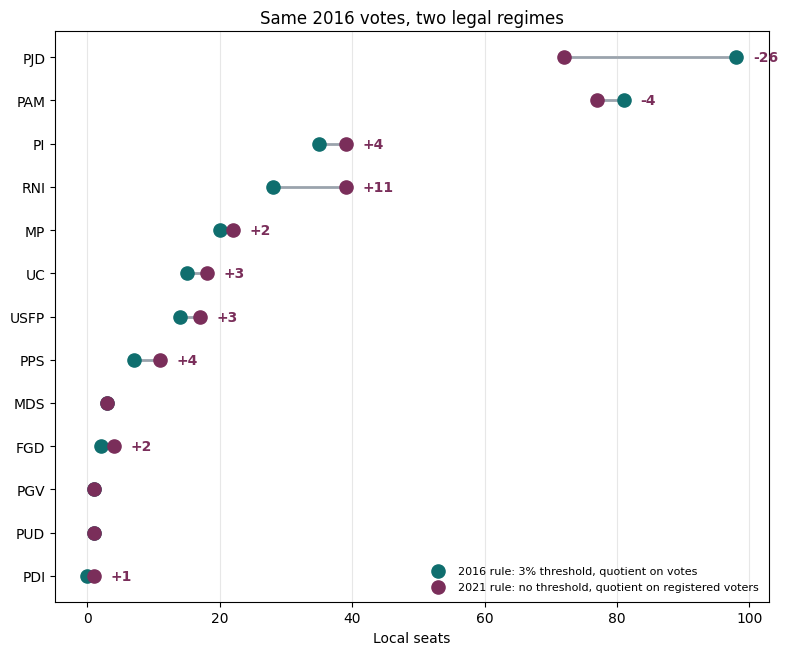

,seats_2016_rule,seats_2021_rule,change
party,,,
PJD,98,72,-26
PAM,81,77,-4
PI,35,39,4
RNI,28,39,11
MP,20,22,2
UC,15,18,3
USFP,14,17,3
PPS,7,11,4
MDS,3,3,0


In [9]:
SV_YEAR = "2016"
RULE_2016, RULE_2021 = "3% · eligible votes (2002, 2016)", "0% · registered voters (2021)"

def same_votes(year, a=RULE_2016, b=RULE_2021):
    t = ENG[year][[a, b]].rename(columns={a: "seats_2016_rule", b: "seats_2021_rule"})
    t["change"] = t["seats_2021_rule"] - t["seats_2016_rule"]
    return t[(t[["seats_2016_rule", "seats_2021_rule"]] > 0).any(axis=1)].sort_values("seats_2016_rule", ascending=False)

SAME_VOTES = {y: same_votes(y) for y in ENG}
sv = SAME_VOTES[SV_YEAR]
lead = sv.index[0]
print(f"{SV_YEAR} votes: {lead} goes from {sv.loc[lead, 'seats_2016_rule']} local seats (2016 rule) to "
      f"{sv.loc[lead, 'seats_2021_rule']} (2021 rule), a change of {sv.loc[lead, 'change']:+d}. "
      f"{int(sv.change.clip(lower=0).sum())} seats change hands in total.")

fig, ax = plt.subplots(figsize=(8, 0.42 * len(sv) + 1.2))
ypos = range(len(sv))[::-1]
ax.hlines(ypos, sv.seats_2016_rule, sv.seats_2021_rule, color="#9AA3AD", lw=2, zorder=1)
ax.scatter(sv.seats_2016_rule, ypos, s=90, color="#0F6E6E", zorder=2, label="2016 rule: 3% threshold, quotient on votes")
ax.scatter(sv.seats_2021_rule, ypos, s=90, color="#7A2E5A", zorder=2, label="2021 rule: no threshold, quotient on registered voters")
for yy, (p, r) in zip(ypos, sv.iterrows()):
    if r.change: ax.text(max(r.seats_2016_rule, r.seats_2021_rule) + 2.5, yy, f"{int(r.change):+d}", va="center", color="#7A2E5A", fontweight="bold")
ax.set_yticks(list(ypos)); ax.set_yticklabels(sv.index); ax.set_xlabel("Local seats"); ax.grid(axis="x", alpha=.3)
ax.set_title(f"Same {SV_YEAR} votes, two legal regimes"); ax.legend(loc="lower right", fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig("fig_same_votes.png", dpi=150); plt.show()
sv


## 3 · Constituency KPIs: competition and integrity

In [10]:
def constituency_kpis(res_year, rule):
    rows = []
    for c, g in res_year.groupby("circonscription"):
        v = g.set_index("party")["votes"].astype(float)
        seats = int(g["seats"].iloc[0])
        s = allocate_seats(v, seats, rule.threshold, rule.quota_basis, g["registered"].iloc[0])
        winners, losers = v[s > 0], v[s == 0]
        margin = (winners.min() - losers.max()) / v.sum() * 100 if len(losers) else np.nan
        rows.append({"circonscription": c, "province": g["province"].iloc[0], "seats": seats,
                     "registered": g["registered"].iloc[0], "voters": g["voters"].iloc[0],
                     "turnout": g["voters"].iloc[0] / g["registered"].iloc[0] if g["registered"].iloc[0] else np.nan,
                     "top_party": v.idxmax(), "top_share": v.max() / v.sum(),
                     "ENP_votes": enp(v), "last_seat_margin_pct": margin,
                     "multi_seat_top": int(s.max() > 1)})
    return pd.DataFrame(rows)

CONST = {y: constituency_kpis(results[results.year == y], RULES.loc[y]) for y in sorted(results.year.unique())}
for y, d in CONST.items():
    print(f"{y}: median last-seat margin {d.last_seat_margin_pct.median():.2f}% | "
          f"{(d.last_seat_margin_pct < 1).mean():.0%} of constituencies decided by <1 pt | "
          f"top party took >1 seat in {d.multi_seat_top.mean():.0%}")
CONST[sorted(CONST)[-1]].head()

2002: median last-seat margin 3.32% | 15% of constituencies decided by <1 pt | top party took >1 seat in 15%
2007: median last-seat margin 1.72% | 35% of constituencies decided by <1 pt | top party took >1 seat in 8%
2011: median last-seat margin 1.88% | 29% of constituencies decided by <1 pt | top party took >1 seat in 29%
2016: median last-seat margin 2.73% | 25% of constituencies decided by <1 pt | top party took >1 seat in 33%
2021: median last-seat margin 3.50% | 21% of constituencies decided by <1 pt | top party took >1 seat in 0%


,circonscription,province,seats,registered,voters,turnout,top_party,top_share,ENP_votes,last_seat_margin_pct,multi_seat_top
0,Agadir - Ida-ou-Tanane,Agadir Ida Ou Tanane,4,322429.0,116590.0,0.361599,RNI,0.516849,3.237546,0.012202,0
1,Al-Fida - Mers-Sultan,Casablanca,3,160448.0,31833.0,0.198401,RNI,0.370824,4.919822,4.666493,0
2,Al-Haouz,Al Haouz,4,324701.0,223719.0,0.689000,RNI,0.340501,4.886531,3.642684,0
3,Al-Hoceïma,Al Hoceima,4,234940.0,123931.0,0.527501,PI,0.219082,6.598716,0.466825,0
4,Aousserd,Aousserd,2,11538.0,9357.0,0.810972,PI,0.508298,2.790671,1.304954,0


## 4 · Forensics (integrity signals)

These are signals, not proof. Cross-check every anomaly with Constitutional Court rulings and observer reports before drawing any conclusion.

In [11]:
def forensics(d, res_year):
    t = d["turnout"].dropna()
    fp = stats.spearmanr(d["turnout"], d["top_share"], nan_policy="omit")
    digits = res_year["votes"].astype(int).abs()
    digits = digits[digits >= 100] % 10
    chi = stats.chisquare(np.bincount(digits, minlength=10))
    z = (d["turnout"] - t.mean()) / t.std()
    return {"turnout_mean": round(t.mean(), 3), "turnout_sd": round(t.std(), 3), "turnout_skew": round(stats.skew(t), 2),
            "share_turnout_gt_80pct": round((t > .8).mean(), 3),
            "fingerprint_rho": round(fp.correlation, 3), "fingerprint_p": round(fp.pvalue, 4),
            "last_digit_chi2_p": round(chi.pvalue, 4),
            "turnout_outliers_|z|>2.5": ", ".join(d.loc[z.abs() > 2.5, "circonscription"])}

FORENSICS = pd.DataFrame({y: forensics(CONST[y], results[results.year == y]) for y in CONST}).T
FORENSICS

,turnout_mean,turnout_sd,turnout_skew,share_turnout_gt_80pct,fingerprint_rho,fingerprint_p,last_digit_chi2_p,turnout_outliers_|z|>2.5
2002,0.451,0.1,0.94,0.011,0.166,0.1164,0.5643,"Aousserd, Salé - Al-Jadida, Salé - Médina"
2007,0.398,0.111,0.56,0.0,-0.061,0.5559,0.4973,"Aousserd, Assa-Zag"
2011,0.487,0.098,0.73,0.0,-0.311,0.0026,0.138,"Assa-Zag, Tarfaya"
2016,0.451,0.094,0.76,0.0,-0.301,0.0035,0.8457,"Aousserd, Tarfaya"
2021,0.54,0.163,-0.56,0.033,0.189,0.0706,0.6292,


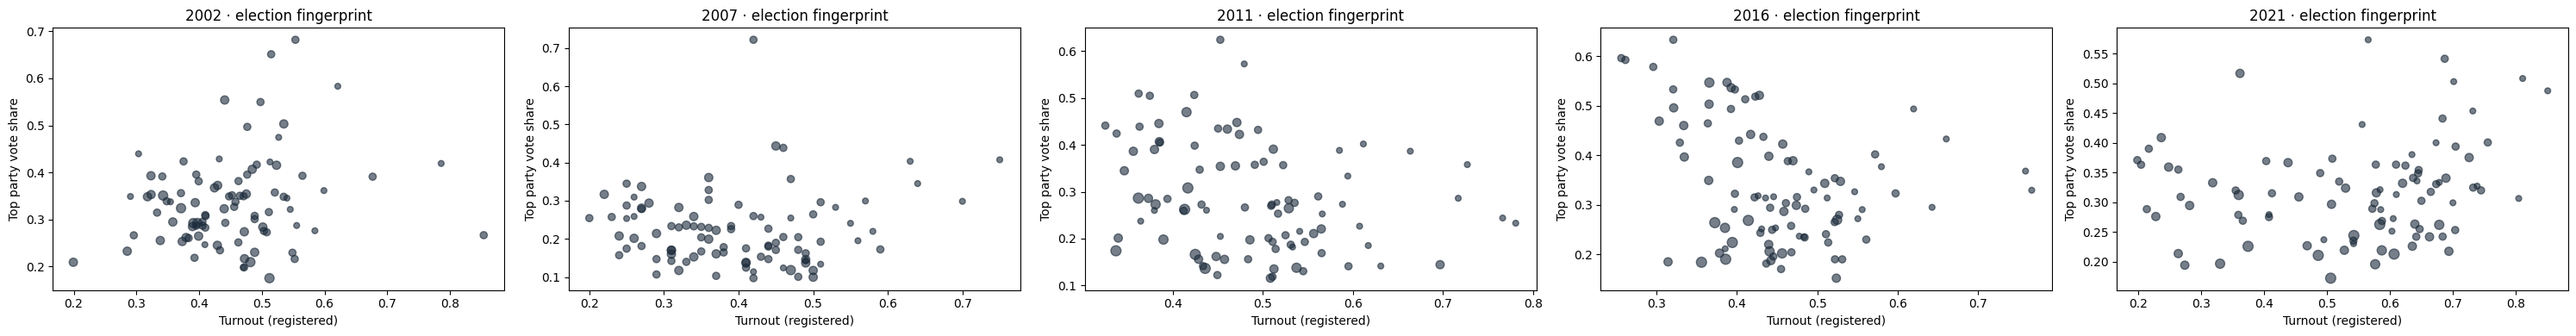

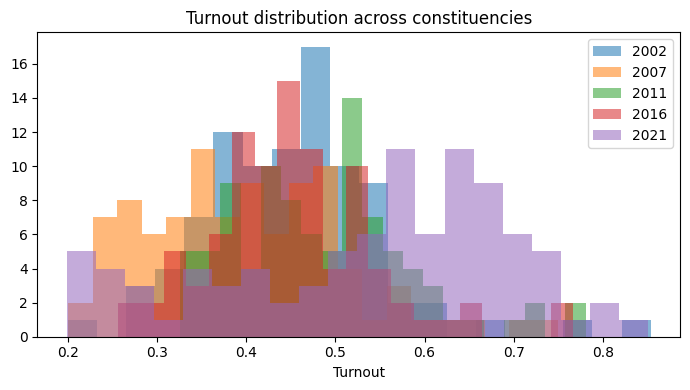

In [12]:
fig, axes = plt.subplots(1, len(CONST), figsize=(6 * len(CONST), 4), squeeze=False)
for ax, (y, d) in zip(axes[0], CONST.items()):
    ax.scatter(d["turnout"], d["top_share"], s=d["seats"] * 12, alpha=.6, color="#1B2A3A")
    ax.set_title(f"{y} · election fingerprint"); ax.set_xlabel("Turnout (registered)"); ax.set_ylabel("Top party vote share")
plt.tight_layout(); plt.savefig("fig_fingerprint.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for y, d in CONST.items():
    ax.hist(d["turnout"].dropna(), bins=20, alpha=.55, label=y)
ax.set_title("Turnout distribution across constituencies"); ax.set_xlabel("Turnout"); ax.legend()
plt.tight_layout(); plt.savefig("fig_turnout_hist.png", dpi=150); plt.show()

## 5 · Census × law: who weighs more, who registers

Malapportionment and vote weight show how many inhabitants stand behind each seat. Rural over-representation is a classic tool for keeping notables strong.

In [13]:
def census_kpis(d, census):
    m = d.groupby("province").agg(seats=("seats","sum"), registered=("registered","sum"),
                                  voters=("voters","sum")).reset_index().merge(census, on="province", how="left")
    unmatched = m["population"].isna().sum()
    m["pop_per_seat"] = m["population"] / m["seats"]
    m["registration_rate"] = m["registered"] / m["pop18"]
    m["real_turnout"] = m["voters"] / m["pop18"]
    summary = {"MAL_index_pct": round(malapportionment(m["seats"], m["population"]), 2),
               "vote_weight_ratio_max_min": round(m["pop_per_seat"].max() / m["pop_per_seat"].min(), 2),
               "registration_rate_national": round(m["registered"].sum() / m["pop18"].sum(), 3),
               "real_turnout_national": round(m["voters"].sum() / m["pop18"].sum(), 3),
               "corr_urban_vs_pop_per_seat": round(stats.spearmanr(m["urban_rate"], m["pop_per_seat"]).correlation, 3),
               "unmatched_provinces": int(unmatched)}
    return m, summary

CENSUS_MERGED, CENSUS_SUMMARY = {}, {}
for y, d in CONST.items():
    CENSUS_MERGED[y], CENSUS_SUMMARY[y] = census_kpis(d, census_of(y))
pd.DataFrame(CENSUS_SUMMARY).T

,MAL_index_pct,vote_weight_ratio_max_min,registration_rate_national,real_turnout_national,corr_urban_vs_pop_per_seat,unmatched_provinces
2002,8.91,42.29,0.768,0.331,0.064,0.0
2007,9.58,49.22,0.835,0.308,0.049,0.0
2011,11.35,177.01,0.601,0.273,0.143,0.0
2016,11.35,177.01,0.703,0.298,0.143,0.0
2021,11.35,177.01,0.784,0.403,0.143,0.0


## 6 · Socio-economic profile of the vote (province level · beware the ecological fallacy)

In [14]:
def vote_profile(results_year, census, vars_=("urban_rate","illiteracy","unemployment")):
    shares = (results_year.groupby(["province","party"])["votes"].sum()
              .groupby(level=0).transform(lambda x: x / x.sum()).unstack())
    df = shares.join(census.set_index("province")[list(vars_)], how="inner")
    tbl = pd.DataFrame({v: {p: stats.spearmanr(df[v], df[p]).correlation for p in shares.columns} for v in vars_})
    return tbl.round(2)

def turnout_model(m):
    # Standardised OLS: real turnout ~ urbanisation + illiteracy + unemployment (province level).
    X = m[["urban_rate","illiteracy","unemployment"]].dropna()
    y = m.loc[X.index, "real_turnout"]
    Xs = (X - X.mean()) / X.std(); ys = (y - y.mean()) / y.std()
    A = np.column_stack([np.ones(len(Xs)), Xs.values])
    beta, *_ = np.linalg.lstsq(A, ys.values, rcond=None)
    r2 = 1 - ((ys.values - A @ beta) ** 2).sum() / ((ys.values - ys.mean()) ** 2).sum()
    return pd.Series(beta[1:], index=X.columns).round(3), round(r2, 3)

PROFILE = {}
for y in CONST:
    PROFILE[y] = vote_profile(results[results.year == y], census_of(y))
    b, r2 = turnout_model(CENSUS_MERGED[y])
    print(f"\n{y} · Spearman correlations (party vote share vs census variable):"); display(PROFILE[y])
    print(f"Real turnout model, standardised betas (R² = {r2}):"); print(b.to_string())


2002 · Spearman correlations (party vote share vs census variable):


,urban_rate,illiteracy,unemployment
MP,-0.34,0.19,-0.05
PI,0.04,0.09,0.17
PJD,0.37,-0.43,0.04
PND,-0.27,0.24,-0.31
PPS,-0.14,0.17,0.01
PSU,-0.00,-0.02,0.29
RNI,-0.33,0.24,-0.05
UC,0.04,-0.03,-0.16
USFP,0.20,-0.20,-0.09


Real turnout model, standardised betas (R² = 0.198):
urban_rate     -0.589
illiteracy     -0.088
unemployment    0.145

2007 · Spearman correlations (party vote share vs census variable):


,urban_rate,illiteracy,unemployment
ADL,-0.01,0.02,-0.09
ALAHD,-0.03,-0.01,0.12
BH,0.05,-0.09,0.22
CNI,0.03,0.02,0.12
FFD,-0.28,0.22,-0.10
ICD,-0.22,0.19,-0.12
MDS,-0.20,0.26,-0.05
MP,0.05,-0.17,0.12
PA,0.11,-0.00,0.10
PADS,0.28,-0.32,0.23


Real turnout model, standardised betas (R² = 0.146):
urban_rate     -0.271
illiteracy      0.209
unemployment    0.301

2011 · Spearman correlations (party vote share vs census variable):


,urban_rate,illiteracy,unemployment
AHD,-0.20,0.27,-0.14
FFD,-0.26,0.42,-0.20
MDS,-0.28,0.21,-0.21
MP,-0.01,0.26,0.05
PA,0.04,-0.05,-0.17
PAM,-0.04,-0.02,0.01
PCS,-0.03,-0.05,-0.29
PDN,-0.02,0.09,-0.26
PEDD,-0.08,0.07,-0.19
PGV,-0.00,0.03,-0.08


... (2 outputs left out)

Real turnout model, standardised betas (R² = 0.309):
urban_rate     -1.015
illiteracy     -0.833
unemployment    0.141



2021 · Spearman correlations (party vote share vs census variable):


,urban_rate,illiteracy,unemployment
AFG,0.26,-0.12,0.01
AHD,0.20,-0.19,0.11
FFD,0.28,-0.07,0.16
MDS,0.22,-0.22,0.00
MP,-0.13,0.26,0.03
NEO,0.14,-0.20,0.12
PA,0.22,-0.17,0.05
PAM,0.03,0.19,0.16
PAN,0.08,-0.11,0.07
PCS,0.12,-0.14,-0.14


Real turnout model, standardised betas (R² = 0.325):
urban_rate     -1.046
illiteracy     -0.735
unemployment    0.161


## 7 · Scorecard: Free · Fair · Decisive · Legitimacy

The cut-offs below are **analytical conventions**, not universal norms. Justify them in your write-up.

In [15]:
def scorecard(y):
    k, f, c = KPI_NATIONAL.loc[y], FORENSICS.loc[y], CENSUS_SUMMARY[y]
    rows = [
     ("Free","Parties winning seats",k.parties_with_seats, "≥5 → plural competition", k.parties_with_seats >= 5),
     ("Free","Pedersen volatility",k.pedersen_volatility, "≥10 → voters really switch", (k.pedersen_volatility or 0) >= 10),
     ("Fair","Gallagher index",k.gallagher, "≤5 → low distortion", k.gallagher <= 5),
     ("Fair","Malapportionment (MAL %)",c["MAL_index_pct"], "≤5 → equal vote weight", c["MAL_index_pct"] <= 5),
     ("Integrity","Fingerprint ρ",f.fingerprint_rho, "<0.3 → no stuffing signal", f.fingerprint_rho < .3),
     ("Integrity","Turnout >80% share",f.share_turnout_gt_80pct, "<2% → no implausible turnout", f.share_turnout_gt_80pct < .02),
     ("Decisive","Winner seat share",k.winner_seat_share, "≥0.4 → winner can lead", k.winner_seat_share >= .4),
     ("Decisive","Parties needed for majority",k.min_parties_majority, "≤2 → simple coalition", k.min_parties_majority <= 2),
     ("Legitimacy","Real turnout (pop 18+)",c["real_turnout_national"], "≥0.5 → broad participation", c["real_turnout_national"] >= .5),
    ]
    sc = pd.DataFrame(rows, columns=["test","kpi","value","benchmark","meets_benchmark"])
    sc["year"] = y
    return sc

SCORECARD = pd.concat([scorecard(y) for y in CONST])
SCORECARD.pivot_table(index=["test","kpi","benchmark"], columns="year", values="value", aggfunc="first")

year                                                                  2002    2007    2011    2016    2021
test       kpi                         benchmark                                                          
Decisive   Parties needed for majority ≤2 → simple coalition         3.000   4.000   3.000   2.000   2.000
           Winner seat share           ≥0.4 → winner can lead        0.200   0.156   0.275   0.321   0.282
Fair       Gallagher index             ≤5 → low distortion           3.330   5.680   5.860   6.030   6.440
           Malapportionment (MAL %)    ≤5 → equal vote weight        8.910   9.580  11.350  11.350  11.350
Free       Parties winning seats       ≥5 → plural competition       9.000  24.000  14.000  12.000  10.000
           Pedersen volatility         ≥10 → voters really switch      NaN  36.200  31.900  18.700  30.200
Integrity  Fingerprint ρ               <0.3 → no stuffing signal     0.166  -0.061  -0.311  -0.301   0.189
           Turnout >80% share          <2% → no implausible turnout  0.011   0.000   0.000   0.000   0.033
Legitimacy Real turnout (pop 18+)      ≥0.5 → broad participation    0.331   0.308   0.273   0.298   0.403

## 9 · Power module: from the largest party to the split of powers

This extends the chain past the election: **largest party → head of government → government → who holds which powers**. The data are entered by hand (they come from government lists and royal communiqués, not from election results). They mirror the *Pouvoir* sheet of the dashboard. **These are real, sourced values** (government lists and royal communiqués).

| KPI | Formula | What it tests |
|---|---|---|
| Formation delay | government date − election date | does the winner form a government on its own terms? |
| Gamson ratio | winner's share of portfolios ÷ winner's share of coalition seats | is the winner under-represented in its own government? |
| Non-partisan share | non-partisan members ÷ members | how much of the cabinet escapes the vote |
| Sovereignty ministries held by non-partisans | out of 6 (Interior, Foreign Affairs, Justice, Habous, Defence, SGG) | the core of the "monarchy powers" box |
| Royal dismissals | count per term | who can remove ministers |

Rows for the Jettou (2002) and El Fassi (2007) governments hold what is established here (dates, seats of the largest party, key ministries); coalition seats and the number of posts are still **to collect**, so their Gamson ratio is empty. Their entries are from memory of the government lists and are flagged *verify*.


In [16]:
POWER = pd.DataFrame([
 # gov, election_year, election, gov_date, coalition_seats, members, winner_members, winner_seats, nonpartisan, sov_nonpartisan, sov_winner, royal_dismissals
 ("Jettou","2002","2002-09-27","2002-11-07",np.nan,np.nan,np.nan,50,np.nan,4,1,np.nan),
 ("El Fassi","2007","2007-09-07","2007-10-15",np.nan,np.nan,np.nan,52,np.nan,5,0,np.nan),
 ("Benkirane I","2011","2011-11-25","2012-01-03",217,30,11,107,5,3,2,0),
 ("El Othmani","2016","2016-10-07","2017-04-05",240,39,11,125,np.nan,5,0,2),
 ("Akhannouch","2021","2021-09-08","2021-10-07",269,24,7,102,np.nan,5,0,np.nan),   # 7 RNI members of 24, as in PORTFOLIOS
], columns=["government","year","election","gov_date","coalition_seats","members","winner_members","winner_seats",
            "nonpartisan","sov_nonpartisan","sov_winner","royal_dismissals"])
# Who led the government: the largest party? its own leader? (2002: Driss Jettou, non-partisan; 2016: El Othmani replaced Benkirane)
POWER["pm_from_winner"] = [False, True, True, True, True]
POWER["pm_is_winner_leader"] = [False, True, True, False, True]
POWER["formation_days"] = (pd.to_datetime(POWER.gov_date) - pd.to_datetime(POWER.election)).dt.days
POWER["winner_share_of_coalition"] = POWER.winner_seats / POWER.coalition_seats
POWER["winner_share_of_portfolios"] = POWER.winner_members / POWER.members
POWER["gamson_ratio"] = (POWER.winner_share_of_portfolios / POWER.winner_share_of_coalition).round(2)
POWER["nonpartisan_share"] = POWER.nonpartisan / POWER.members
POWER.set_index("government")[["formation_days","winner_share_of_coalition","winner_share_of_portfolios","gamson_ratio",
                               "nonpartisan_share","sov_nonpartisan","sov_winner","royal_dismissals"]].round(3)

,formation_days,winner_share_of_coalition,winner_share_of_portfolios,gamson_ratio,nonpartisan_share,sov_nonpartisan,sov_winner,royal_dismissals
government,,,,,,,,
Jettou,41,NaN,NaN,NaN,NaN,4,1,NaN
El Fassi,38,NaN,NaN,NaN,NaN,5,0,NaN
Benkirane I,39,0.493,0.367,0.74,0.167,3,2,0.0
El Othmani,180,0.521,0.282,0.54,NaN,5,0,2.0
Akhannouch,29,0.379,0.292,0.77,NaN,5,0,NaN


### After the vote: who gets the government, and the key ministries

`AFTER_VOTE` is the comparison table of the three governments. `KEY_MINISTRIES` lists who held each of the six sovereignty ministries, entered by hand from the government lists; entries marked *(verify)* still need a source check. The counts of ministries held by non-partisans and by the winning party are recomputed from this list and compared with the figures in `POWER`.

In [17]:
KEY_MINISTRIES = pd.DataFrame([
 # ministry, government, minister, party, to_verify
 ("Interior","Jettou","Sahel","Non-partisan",True), ("Interior","El Fassi","Benmoussa","Non-partisan",True),
 ("Foreign Affairs","Jettou","Benaissa","RNI",True), ("Foreign Affairs","El Fassi","Fassi Fihri","Non-partisan",True),
 ("Justice","Jettou","Bouzoubaa","USFP",True), ("Justice","El Fassi","Radi","USFP",True),
 ("Islamic Affairs","Jettou","Toufiq","Non-partisan",True), ("Islamic Affairs","El Fassi","Toufiq","Non-partisan",True),
 ("Defence administration","Jettou","Sbaï","Non-partisan",True), ("Defence administration","El Fassi","Sbaï","Non-partisan",True),
 ("Secretariat-General","Jettou","Rabiaa","Non-partisan",True), ("Secretariat-General","El Fassi","Rabiaa","Non-partisan",True),
 ("Interior","Benkirane I","Laenser","MP",False), ("Interior","El Othmani","Laftit","Non-partisan",False), ("Interior","Akhannouch","Laftit","Non-partisan",False),
 ("Foreign Affairs","Benkirane I","El Othmani","PJD",False), ("Foreign Affairs","El Othmani","Bourita","Non-partisan",False), ("Foreign Affairs","Akhannouch","Bourita","Non-partisan",False),
 ("Justice","Benkirane I","Ramid","PJD",False), ("Justice","El Othmani","Aujjar","RNI",False), ("Justice","Akhannouch","Ouahbi","PAM",False),
 ("Islamic Affairs","Benkirane I","Toufiq","Non-partisan",False), ("Islamic Affairs","El Othmani","Toufiq","Non-partisan",False), ("Islamic Affairs","Akhannouch","Toufiq","Non-partisan",False),
 ("Defence administration","Benkirane I","Loudiyi","Non-partisan",False), ("Defence administration","El Othmani","Loudiyi","Non-partisan",False), ("Defence administration","Akhannouch","Loudiyi","Non-partisan",False),
 ("Secretariat-General","Benkirane I","Dahak","Non-partisan",False), ("Secretariat-General","El Othmani","Hajoui","Non-partisan",True), ("Secretariat-General","Akhannouch","Hajoui","Non-partisan",True),
], columns=["ministry","government","minister","party","to_verify"])
GOV_WINNER = {"Jettou": "USFP", "El Fassi": "PI", "Benkirane I": "PJD", "El Othmani": "PJD", "Akhannouch": "RNI"}
KEY_MINISTRIES["government"] = pd.Categorical(KEY_MINISTRIES.government, list(GOV_WINNER), ordered=True)
KEY_MINISTRIES = KEY_MINISTRIES.sort_values(["government"], kind="stable").astype({"government": str}).reset_index(drop=True)

KEY_COUNTS = KEY_MINISTRIES.groupby("government", sort=False).apply(lambda d: pd.Series({
    "key_nonpartisan": int((d.party == "Non-partisan").sum()),
    "key_winner": int((d.party == GOV_WINNER[d.name]).sum()),
    "key_other_parties": int((~d.party.isin(["Non-partisan", GOV_WINNER[d.name]])).sum())}))
_chk = POWER.set_index("government")[["sov_nonpartisan", "sov_winner"]]
assert (KEY_COUNTS.key_nonpartisan == _chk.sov_nonpartisan).all() and (KEY_COUNTS.key_winner == _chk.sov_winner).all(), "KEY_MINISTRIES and POWER disagree"

_p = POWER.set_index("government")
AFTER_VOTE = pd.DataFrame({
    "Days from election to government": _p.formation_days,
    "Coalition seats": _p.coalition_seats,
    "Winner's share of coalition seats": _p.winner_share_of_coalition.round(3),
    "Winner's share of government posts": _p.winner_share_of_portfolios.round(3),
    "Gamson ratio (1 = proportional)": _p.gamson_ratio,
    "Key ministries held by non-partisans (of 6)": KEY_COUNTS.key_nonpartisan,
    "Key ministries held by the winner": KEY_COUNTS.key_winner,
    "Ministers dismissed by the King during the term": _p.royal_dismissals,
    "Head of government from the largest party": _p.pm_from_winner,
    "Head of government is that party's leader": _p.pm_is_winner_leader,
}).T
display(AFTER_VOTE)
KEY_MINISTRIES.assign(holder=lambda d: d.minister + " · " + d.party + np.where(d.to_verify, " (verify)", "")).pivot(index="ministry", columns="government", values="holder")[list(GOV_WINNER)].reindex(KEY_MINISTRIES.ministry.unique())


government,Jettou,El Fassi,Benkirane I,El Othmani,Akhannouch
Days from election to government,41,38,39,180,29
Coalition seats,NaN,NaN,217.0,240.0,269.0
Winner's share of coalition seats,NaN,NaN,0.493,0.521,0.379
Winner's share of government posts,NaN,NaN,0.367,0.282,0.292
Gamson ratio (1 = proportional),NaN,NaN,0.74,0.54,0.77
Key ministries held by non-partisans (of 6),4,5,3,5,5
Key ministries held by the winner,1,0,2,0,0
Ministers dismissed by the King during the term,NaN,NaN,0.0,2.0,NaN
Head of government from the largest party,False,True,True,True,True
Head of government is that party's leader,False,True,True,False,True


government,Jettou,El Fassi,Benkirane I,El Othmani,Akhannouch
ministry,,,,,
Interior,Sahel · Non-partisan (verify),Benmoussa · Non-partisan (verify),Laenser · MP,Laftit · Non-partisan,Laftit · Non-partisan
Foreign Affairs,Benaissa · RNI (verify),Fassi Fihri · Non-partisan (verify),El Othmani · PJD,Bourita · Non-partisan,Bourita · Non-partisan
Justice,Bouzoubaa · USFP (verify),Radi · USFP (verify),Ramid · PJD,Aujjar · RNI,Ouahbi · PAM
Islamic Affairs,Toufiq · Non-partisan (verify),Toufiq · Non-partisan (verify),Toufiq · Non-partisan,Toufiq · Non-partisan,Toufiq · Non-partisan
Defence administration,Sbaï · Non-partisan (verify),Sbaï · Non-partisan (verify),Loudiyi · Non-partisan,Loudiyi · Non-partisan,Loudiyi · Non-partisan
Secretariat-General,Rabiaa · Non-partisan (verify),Rabiaa · Non-partisan (verify),Dahak · Non-partisan,Hajoui · Non-partisan (verify),Hajoui · Non-partisan (verify)


### Chain transmission: where does the vote stop deciding?

Each link of the chain gets a status from the KPIs above and from sections 1–7. **Strong** means the vote clearly decides at this link; **bounded** means it decides within limits; **weak** means the outcome is mostly set elsewhere.

In [18]:
latest = KPI_NATIONAL.iloc[-1]
p = POWER.set_index("government")
_n = len(POWER)
CHAIN = pd.DataFrame([
 ("Voters → election", "Real turnout (pop 18+), latest election", f"{CENSUS_SUMMARY[sorted(CENSUS_SUMMARY)[-1]]['real_turnout_national']:.0%}", "bounded" if CENSUS_SUMMARY[sorted(CENSUS_SUMMARY)[-1]]['real_turnout_national'] < .5 else "strong"),
 ("Election → largest party", "Gallagher index, latest election", f"{latest.gallagher:.1f}", "bounded" if latest.gallagher > 5 else "strong"),
 ("Largest party → head of government", "Largest party leads the government / its own leader is appointed",
  f"{int(POWER.pm_from_winner.sum())} of {_n} / {int(POWER.pm_is_winner_leader.sum())} of {_n} (2002: non-partisan Jettou; 2016: Benkirane replaced)", "bounded"),
 ("Head of government → government", "Gamson ratio of the winner (2012 → 2017)", f"{p.loc['Benkirane I','gamson_ratio']} → {p.loc['El Othmani','gamson_ratio']}", "weak" if p.loc['El Othmani','gamson_ratio'] < .75 else "bounded"),
 ("Government → powers", "Sovereignty ministries held by non-partisans (" + " → ".join(pd.to_datetime(POWER.gov_date).dt.year.astype(str)) + ")",
  " → ".join(str(int(v)) for v in POWER.sov_nonpartisan) + " of 6", "weak"),
], columns=["link","kpi","value","status"])
CHAIN


,link,kpi,value,status
0,Voters → election,"Real turnout (pop 18+), latest election",40%,bounded
1,Election → largest party,"Gallagher index, latest election",6.4,bounded
2,Largest party → head of government,Largest party leads the government / its own l...,4 of 5 / 3 of 5 (2002: non-partisan Jettou; 20...,bounded
3,Head of government → government,Gamson ratio of the winner (2012 → 2017),0.74 → 0.54,weak
4,Government → powers,Sovereignty ministries held by non-partisans (...,4 → 5 → 3 → 5 → 5 of 6,weak


## 10 · Power module, extended: from posts to power

Section 9 counts who holds which posts. This section adds four measures of **power**, not just posts:

| KPI | Why it matters | Data |
|---|---|---|
| **Weighted Gamson ratio** | Interior counts for more than a secretary of state | Portfolio list by tier: sovereignty = 3, major = 2, minister = 1, junior = 0.5 |
| **"Coloured" technocrats** | Ministers who take a party label just before appointment inflate the party share | Biographies at appointment |
| **Appointments: art. 49 vs art. 92** | Who fills the senior administration: the royal channel or the government channel (LO 02.12) | *Bulletin officiel* |
| **Agenda origin** | Major reforms launched by royal speech or commission vs from the government programme | Royal speeches, government programmes |
| **Budget under sovereignty ministries** | Power measured in money | Finance laws |

**Data status.** The portfolio table uses real totals per party and the real sovereignty-ministry holders, but the split of the other portfolios between *major*, *minister* and *junior* is an **illustrative placeholder**. The weighted Gamson ratio and the weighted non-partisan share therefore remain indicative until the real portfolio lists are coded in `PORTFOLIOS`. The four other measures are empty ("to collect").

In [19]:
TIER_W = {"sovereignty": 3, "major": 2, "minister": 1, "junior": 0.5}
PORTFOLIOS = pd.DataFrame([
 # government, party, sovereignty, major, minister, junior   (totals and sovereignty holders real; tier split = illustrative placeholder, to replace with the real lists)
 ("Benkirane I","PJD",2,2,5,2),("Benkirane I","Istiqlal",0,2,3,1),("Benkirane I","MP",1,0,2,1),("Benkirane I","PPS",0,1,2,1),("Benkirane I","Non-partisan",3,0,1,1),
 ("El Othmani","PJD",0,2,5,4),("El Othmani","RNI",1,3,3,2),("El Othmani","MP",0,1,3,1),("El Othmani","USFP",0,0,2,1),("El Othmani","UC",0,1,1,1),("El Othmani","PPS",0,1,1,1),("El Othmani","Non-partisan",5,0,0,0),
 ("Akhannouch","RNI",0,3,4,0),("Akhannouch","PAM",1,1,3,0),("Akhannouch","Istiqlal",0,1,3,0),("Akhannouch","Non-partisan",5,1,2,0),
], columns=["government","party","sovereignty","major","minister","junior"])
PORTFOLIOS["members"] = PORTFOLIOS[list(TIER_W)].sum(axis=1)
PORTFOLIOS["weighted"] = sum(PORTFOLIOS[t] * w for t, w in TIER_W.items())
WINNER = {"Benkirane I": "PJD", "El Othmani": "PJD", "Akhannouch": "RNI"}

rows = []
for g, d in PORTFOLIOS.groupby("government", sort=False):
    w = d[d.party == WINNER[g]].iloc[0]; p = POWER.set_index("government").loc[g]
    seat_share = p.winner_seats / p.coalition_seats
    rows.append({"government": g, "winner": WINNER[g], "members": int(d.members.sum()),
                 "gamson_simple": round((w.members / d.members.sum()) / seat_share, 2),
                 "gamson_weighted": round((w.weighted / d.weighted.sum()) / seat_share, 2),
                 "nonpartisan_weighted_share": round(d[d.party == "Non-partisan"].weighted.sum() / d.weighted.sum(), 3)})
GAMSON = pd.DataFrame(rows).set_index("government").reindex(POWER.government)   # empty for governments without a coded portfolio list

EXTRA = pd.DataFrame(np.nan, index=list(WINNER), columns=["coloured_technocrats", "appointments_art49_share",
    "major_reforms_royal_origin", "major_reforms_government_origin", "budget_share_sovereignty_ministries"])   # to collect
EXTRA["royal_agenda_share"] = EXTRA.major_reforms_royal_origin / (EXTRA.major_reforms_royal_origin + EXTRA.major_reforms_government_origin)
display(GAMSON); display(EXTRA.round(3))

,winner,members,gamson_simple,gamson_weighted,nonpartisan_weighted_share
government,,,,,
Jettou,NaN,NaN,NaN,NaN,NaN
El Fassi,NaN,NaN,NaN,NaN,NaN
Benkirane I,PJD,30.0,0.74,0.74,0.239
El Othmani,PJD,39.0,0.54,0.39,0.278
Akhannouch,RNI,24.0,0.77,0.63,0.452


,coloured_technocrats,appointments_art49_share,major_reforms_royal_origin,major_reforms_government_origin,budget_share_sovereignty_ministries,royal_agenda_share
Benkirane I,NaN,NaN,NaN,NaN,NaN,NaN
El Othmani,NaN,NaN,NaN,NaN,NaN,NaN
Akhannouch,NaN,NaN,NaN,NaN,NaN,NaN


## 11 · Explorer: map, constituencies, parties, seat flows and the turnout what-if

These are the analyses behind the interactive dashboard, so that every figure shown there can be reproduced here.

| Tool | What it gives |
|---|---|
| `PROVINCE[year]` and `plot_map(year, column)` | results by province (leading party, turnout, real turnout, inhabitants per seat) and the map |
| `constituency_detail(year, name)` | every party's votes, share and seats in one constituency |
| `party_view(party)` | one party across the three elections, and where it is strong |
| `hemicycle(...)` | the 305 local seats drawn as a chamber, one panel per election |
| `FLOWS` | seats kept and seats passing from one party to another between two elections |
| `turnout_whatif(year, delta_pts, area, parties)` | seats if turnout had been higher or lower, in urban or rural provinces, for chosen parties |

Conventions: the eight largest parties keep their name and colour, all others are grouped as *Others*. A province is **urban** when at least half of its population is urban in the census used for that election (`URBAN_CUTOFF`). Constituencies were redrawn between 2002, 2007 and 2011, so seat flows across those elections are computed at national level; from 2011 on they are computed constituency by constituency.

In [20]:
YEARS = sorted(results.year.unique())
MAIN_PARTIES = ["PJD","PAM","PI","RNI","MP","USFP","UC","PPS"]   # PAM was founded in 2008
PARTY_COLORS = dict(zip(MAIN_PARTIES, ["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#4a3aa7","#e34948"]), Others="#A9AFB6")
group_party = lambda p: p if p in MAIN_PARTIES else "Others"
URBAN_CUTOFF = 0.5
AREA = {y: census_of(y).set_index("province")["urban_rate"].ge(URBAN_CUTOFF).map({True: "urban", False: "rural"}) for y in YEARS}

def seats_by_constituency(res_year, rule):
    # Seats per party in every constituency (rows = constituencies) under one rule.
    out = {c: allocate_seats(g.set_index("party")["votes"], int(g["seats"].iloc[0]), rule.threshold, rule.quota_basis, g["registered"].iloc[0])
           for c, g in res_year.groupby("circonscription")}
    return pd.DataFrame(out).T.fillna(0).astype(int)

SEATS_CONST = {y: seats_by_constituency(results[results.year == y], RULES.loc[y]) for y in YEARS}

def province_results(year):
    r = results[results.year == year]
    p = r.drop_duplicates("circonscription").groupby("province").agg(constituencies=("circonscription", "size"), seats=("seats", "sum"),
                                                                      registered=("registered", "sum"), voters=("voters", "sum"))
    v = r.groupby(["province", "party"])["votes"].sum().unstack(fill_value=0)
    p["valid_votes"], p["leading_party"], p["leading_share"] = v.sum(axis=1), v.idxmax(axis=1), v.max(axis=1) / v.sum(axis=1)
    p["turnout"] = p.voters / p.registered
    p = p.join(census_of(year).set_index("province")[["population", "pop18", "urban_rate"]])
    p["real_turnout"], p["pop_per_seat"], p["area"] = p.voters / p.pop18, p.population / p.seats, AREA[year]
    return p

PROVINCE = {y: province_results(y) for y in YEARS}
print("Constituencies by type of province:", {y: results[results.year == y].drop_duplicates("circonscription").province.map(AREA[y]).value_counts().to_dict() for y in YEARS})
PROVINCE[YEARS[-1]].sort_values("turnout", ascending=False).head(8).round(3)


Constituencies by type of province: {'2002': {'rural': 48, 'urban': 43}, '2007': {'rural': 50, 'urban': 45}, '2011': {'urban': 51, 'rural': 41}, '2016': {'urban': 51, 'rural': 41}, '2021': {'urban': 51, 'rural': 41}}


,constituencies,seats,registered,voters,valid_votes,leading_party,leading_share,turnout,population,pop18,urban_rate,real_turnout,pop_per_seat,area
province,,,,,,,,,,,,,,
Tarfaya,1,2.0,13129.0,11170.0,9422.0,RNI,0.488,0.851,13028,8823,0.613,1.266,6514.000,urban
Aousserd,1,2.0,11538.0,9357.0,7893.0,PI,0.508,0.811,2396,1971,0.000,4.747,1198.000,rural
Assa-Zag,1,2.0,24169.0,19449.0,16405.0,PAM,0.306,0.805,26947,16923,0.690,1.149,13473.500,urban
Boulemane,1,3.0,112821.0,85236.0,71897.0,RNI,0.401,0.755,197475,124488,0.332,0.685,65825.000,rural
Moulay Yacoub,1,2.0,89775.0,66308.0,55931.0,PAM,0.327,0.739,172311,105833,0.136,0.627,86155.500,rural
Sidi Ifni,1,2.0,95828.0,70117.0,59144.0,RNI,0.454,0.732,115055,77938,0.269,0.900,57527.500,rural
Chichaoua,1,4.0,225013.0,163337.0,137775.0,PAM,0.375,0.726,369494,224431,0.168,0.728,92373.500,rural
Taounate,2,6.0,328200.0,237666.0,200472.0,RNI,0.357,0.724,660736,410581,0.128,0.579,110122.667,rural


75 of 75 provinces have an outline


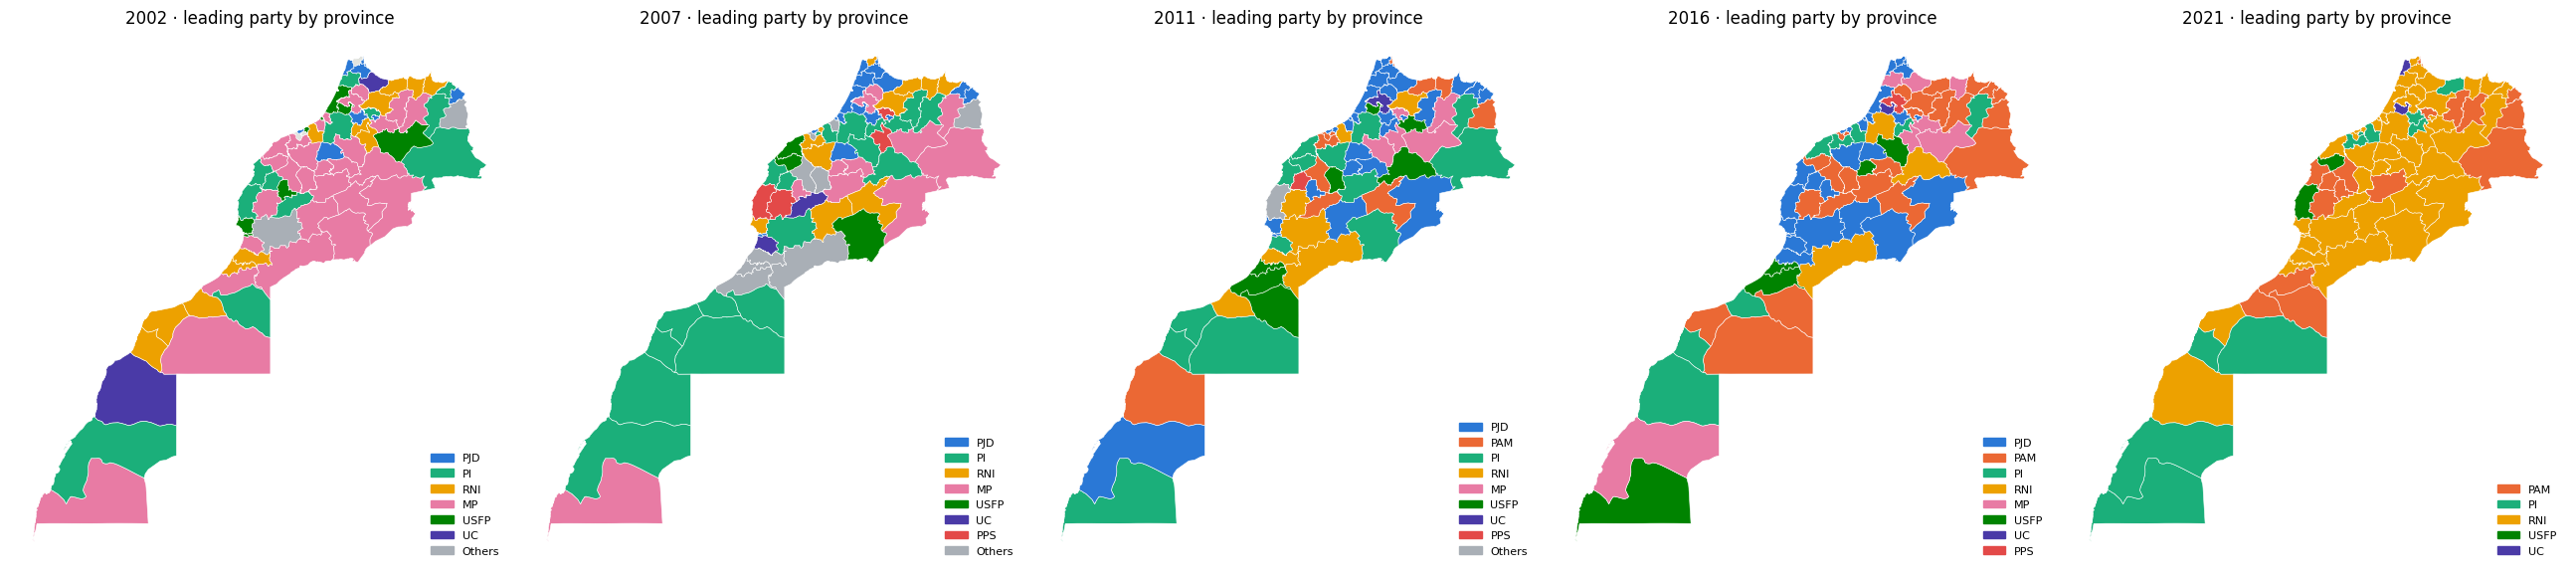

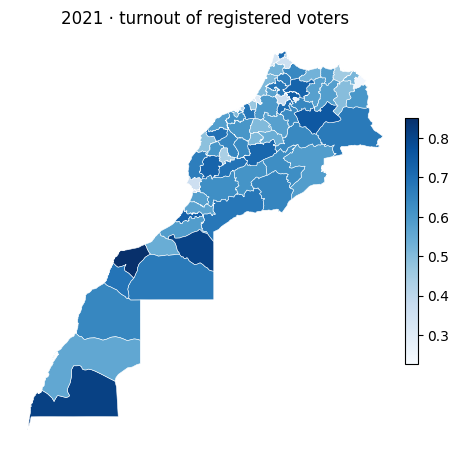

In [21]:
BOUNDARIES_URL = "https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/MAR/ADM2/geoBoundaries-MAR-ADM2_simplified.geojson"
_ALIAS = {"taroudant": "taroudannt", "rhamna": "rehamna", "tangierassilah": "tangerassilah", "mohammedia": "mohammadia",
          "elkelaatessraghna": "elkelaadessraghna", "fquihbensaleh": "fquihbensalah"}

def load_boundaries(path=PATHS["boundaries"]):
    # Province outlines as {province (census spelling): [rings]}. Names in the file mix French, English, Arabic and Tifinagh.
    import json, re, requests
    if not os.path.exists(path):
        open(path, "wb").write(requests.get(BOUNDARIES_URL, timeout=120).content)
    names, shapes = {province_key(p): p for p in CENSUS["2014"].province}, {}
    for ft in json.load(open(path, encoding="utf-8"))["features"]:
        n = re.sub(r"[^\x00-\u024F]+", " ", ft["properties"]["shapeName"]).strip()
        n = re.sub(r"^(Province|Pr[ée]fecture)\s+(de\s+|d'|of\s+)?", "", n, flags=re.I)
        k = province_key(re.sub(r"\s+(Province|Prefecture)$", "", n.strip(), flags=re.I)); k = _ALIAS.get(k, k)
        polys = ft["geometry"]["coordinates"] if ft["geometry"]["type"] == "MultiPolygon" else [ft["geometry"]["coordinates"]]
        if k in names: shapes[names[k]] = [np.array(poly[0]) for poly in polys]
    return shapes

BOUNDARIES = load_boundaries()
print(f"{len(BOUNDARIES)} of {CENSUS['2014'].province.nunique()} provinces have an outline")
# The outlines are today's 75 provinces. For elections that use the 2004 census, each outline shows the province it belonged to then.
PROVINCE_2004 = {
 "Aousserd": "Aousserd",
 "Oued Ed-Dahab": "Oued Ed Dahab",
 "Boujdour": "Boujdour",
 "Laâyoune": "Laayoune",
 "Tarfaya": "Laayoune",
 "Assa-Zag": "Assa Zag",
 "Es-Semara": "Es Semara",
 "Guelmim": "Guelmim",
 "Tan-Tan": "Tan Tan",
 "Tata": "Tata",
 "Agadir Ida Ou Tanane": "Agadir Ida Ou Tanane",
 "Chtouka Ait Baha": "Chtouka Ait Baha",
 "Inezgane Ait Melloul": "Inezgane Ait Melloul",
 "Ouarzazate": "Ouarzazate",
 "Sidi Ifni": "Tiznit",
 "Taroudannt": "Taroudannt",
 "Tinghir": "Ouarzazate",
 "Tiznit": "Tiznit",
 "Zagora": "Zagora",
 "Kénitra": "Kenitra",
 "Sidi Kacem": "Sidi Kacem",
 "Sidi Slimane": "Kenitra",
 "Benslimane": "Benslimane",
 "Berrechid": "Settat",
 "Khouribga": "Khouribga",
 "Settat": "Settat",
 "Al Haouz": "Al Haouz",
 "Chichaoua": "Chichaoua",
 "El Kelâa des  Sraghna": "El Kelaa des Sraghna",
 "Essaouira": "Essaouira",
 "Marrakech": "Marrakech",
 "Rehamna": "El Kelaa des Sraghna",
 "Berkane": "Berkane",
 "Driouch": "Nador",
 "Figuig": "Figuig",
 "Jerada": "Jerada",
 "Nador": "Nador",
 "Oujda-Angad": "Oujda Angad",
 "Taourirt": "Taourirt",
 "Casablanca": "Casablanca",
 "Médiouna": "Mediouna",
 "Mohammadia": "Mohammadia",
 "Nouaceur": "Nouaceur",
 "Khémisset": "Khemisset",
 "Rabat": "Rabat",
 "Salé": "Sale",
 "Skhirate- Témara": "Skhirate Temara",
 "El Jadida": "El Jadida",
 "Safi": "Safi",
 "Sidi Bennour": "El Jadida",
 "Youssoufia": "Safi",
 "Azilal": "Azilal",
 "Béni Mellal": "Beni Mellal",
 "Fquih Ben Salah": "Beni Mellal",
 "Meknès": "Meknes",
 "El Hajeb": "El Hajeb",
 "Errachidia": "Errachidia",
 "Ifrane": "Ifrane",
 "Khénifra": "Khenifra",
 "Midelt": "Khenifra",
 "Boulemane": "Boulemane",
 "Fès": "Fes",
 "Sefrou": "Sefrou",
 "Moulay Yacoub": "Moulay Yacoub",
 "Al Hoceima": "Al Hoceima",
 "Guercif": "Taza",
 "Taounate": "Taounate",
 "Taza": "Taza",
 "Chefchaouen": "Chefchaouen",
 "Fahs-Anjra": "Fahs Anjra",
 "Larache": "Larache",
 "Ouezzane": "Sidi Kacem",
 "Tanger-Assilah": "Tanger Assilah",
 "Tétouan": "Tetouan",
 "M'Diq-Fnideq": "Tetouan"
}

def plot_map(year, column="turnout", ax=None, title=None):
    # Province map. Numeric columns use a blue scale; 'leading_party' uses the party colours.
    from matplotlib.collections import PolyCollection
    from matplotlib.patches import Patch
    p, ax = PROVINCE[year], ax or plt.subplots(figsize=(6, 6.4))[1]
    old = CENSUS_FOR[year] == "2004"
    polys, vals = zip(*[(ring, p[column].get(PROVINCE_2004.get(prov, prov) if old else prov)) for prov, rings in BOUNDARIES.items() for ring in rings])
    if column == "leading_party":
        pc = PolyCollection(polys, facecolors=[PARTY_COLORS[group_party(v)] if isinstance(v, str) else "#E1E3DE" for v in vals], edgecolors="white", linewidths=.4)
        shown = [k for k in PARTY_COLORS if k in {group_party(v) for v in vals if isinstance(v, str)}]
        ax.legend(handles=[Patch(color=PARTY_COLORS[k], label=k) for k in shown], loc="lower right", frameon=False, fontsize=8)
    else:
        pc = PolyCollection(polys, array=np.array(vals, dtype=float), cmap="Blues", edgecolors="white", linewidths=.4)
        plt.colorbar(pc, ax=ax, shrink=.5, pad=.01)
    ax.add_collection(pc); ax.autoscale_view(); ax.set_aspect(1 / np.cos(np.radians(28.5))); ax.axis("off")
    ax.set_title(title or f"{year} · {column}")
    return ax

fig, axes = plt.subplots(1, len(YEARS), figsize=(5.2 * len(YEARS), 6))
for ax, y in zip(axes, YEARS): plot_map(y, "leading_party", ax, f"{y} · leading party by province")
plt.tight_layout(); plt.savefig("fig_map_leading_party.png", dpi=150); plt.show()
plot_map(YEARS[-1], "turnout", title=f"{YEARS[-1]} · turnout of registered voters"); plt.savefig("fig_map_turnout.png", dpi=150); plt.show()


In [22]:
def constituency_detail(year, name):
    # Votes, share and seats of every party in one constituency, with the seats there at the other elections.
    g = results[(results.year == year) & (results.circonscription == name)]
    if g.empty: raise KeyError(f"No constituency named {name!r} in {year}")
    d = g.set_index("party")[["votes"]].query("votes > 0").sort_values("votes", ascending=False)
    d["share"] = (d.votes / d.votes.sum()).round(4)
    for y in YEARS:      # only the elections where this constituency exists under the same name
        if name in SEATS_CONST[y].index: d[f"seats_{y}"] = SEATS_CONST[y].loc[name].reindex(d.index).fillna(0).astype(int)
    h = g.iloc[0]
    print(f"{name} ({h.province}, {AREA[year].get(h.province)}) · {year}: {int(h.seats)} seats, {int(h.registered):,} registered"
          f"{' (estimated)' if h.registered_estimated else ''}, turnout {h.voters / h.registered:.1%}")
    return d

def party_view(party):
    # One party across the elections: seats, rank, vote share, constituencies where it comes first, strongest provinces.
    rows = {}
    for y in YEARS:
        t = SEATS[y].sort_values("seats_local", ascending=False)
        if party not in t.index or t.loc[party, "votes"] == 0: continue
        first = results[results.year == y].sort_values("votes", ascending=False).drop_duplicates("circonscription").party.eq(party).sum()
        share = results[(results.year == y) & (results.party == party)].groupby("province")["votes"].sum() / PROVINCE[y].valid_votes
        rows[y] = {"local_seats": int(t.loc[party, "seats_local"]), "rank": int(list(t.index).index(party) + 1),
                   "vote_share": round(t.loc[party, "votes"] / t.votes.sum(), 4), "constituencies_first": int(first),
                   "strongest_provinces": ", ".join(f"{p} {v:.0%}" for p, v in share.nlargest(3).items())}
    return pd.DataFrame(rows).T

display(constituency_detail(YEARS[-1], results.circonscription.iloc[0]))
PARTY_VIEW = {p: party_view(p) for p in MAIN_PARTIES}
for p in ["PJD", "RNI"]: print(f"\n{p}"); display(PARTY_VIEW[p])


Benslimane (Benslimane, rural) · 2021: 3 seats, 134,988 registered (estimated), turnout 68.4%


,votes,share,seats_2002,seats_2007,seats_2011,seats_2016,seats_2021
party,,,,,,,
PI,18849.0,0.2421,1,1,1,1,1
RNI,16743.0,0.2150,1,0,1,1,1
PPS,14582.0,0.1873,0,1,0,0,1
USFP,11065.0,0.1421,1,1,1,0,0
PAM,6657.0,0.0855,0,0,0,0,0
PJD,4550.0,0.0584,0,0,0,1,0
NEO,822.0,0.0106,0,0,0,0,0
PSU,763.0,0.0098,0,0,0,0,0
PA,711.0,0.0091,0,0,0,0,0



PJD


,local_seats,rank,vote_share,constituencies_first,strongest_provinces
2002,45,4,0.1437,20,"Tanger Assilah 38%, Casablanca 33%, Fes 30%"
2007,40,2,0.1093,19,"Larache 36%, Tanger Assilah 32%, Fes 30%"
2011,84,1,0.2278,41,"Inezgane Ait Melloul 51%, Tanger-Assilah 47%, ..."
2016,98,1,0.2721,40,"Inezgane Ait Melloul 63%, Tanger-Assilah 55%, ..."
2021,4,8,0.0425,0,"Assa-Zag 21%, Fès 9%, Taroudannt 9%"



RNI


,local_seats,rank,vote_share,constituencies_first,strongest_provinces
2002,43,5,0.1356,12,"Tan Tan 42%, Benslimane 36%, Laayoune 35%"
2007,34,4,0.0969,13,"Mohammadia 33%, Taounate 30%, Tan Tan 29%"
2011,43,3,0.1133,8,"Tiznit 57%, Tata 39%, Aousserd 32%"
2016,28,4,0.0968,4,"Midelt 32%, Tiznit 32%, Tata 29%"
2021,86,1,0.2766,59,"Tiznit 57%, Agadir Ida Ou Tanane 52%, Fahs-Anj..."


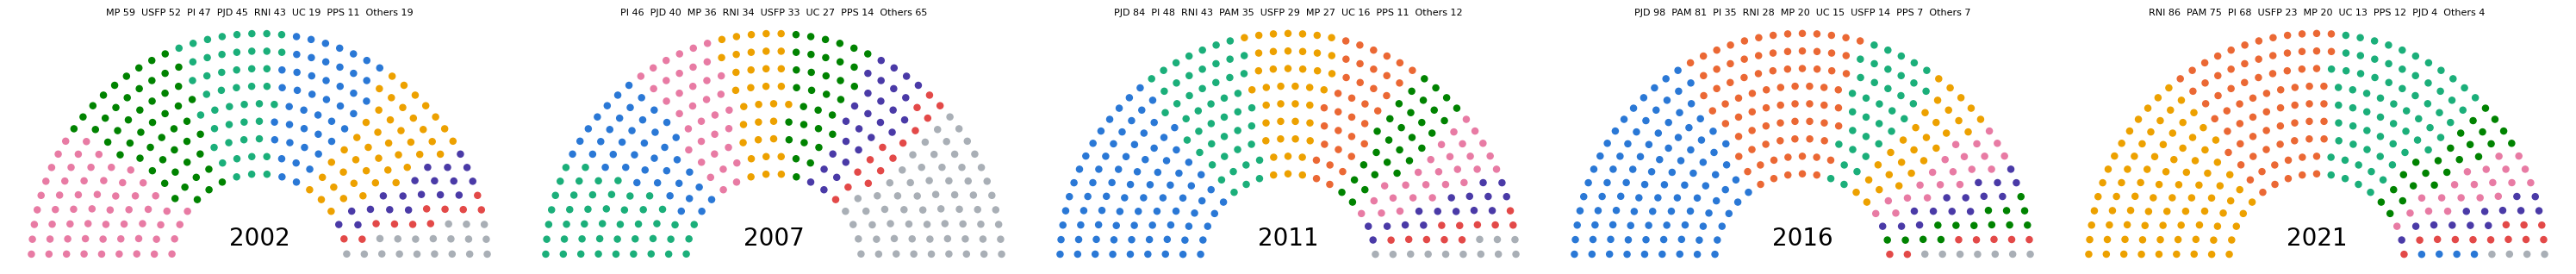


2002-2007 (national level): 238 local seats stay with the same party. Rows = party before, columns = party after.


to,PJD,PI,RNI,MP,USFP,UC,PPS,Others
from,,,,,,,,
PJD,40.0,0.0,0.0,0.0,0.0,0.7,0.3,4.0
PI,0.0,46.0,0.0,0.0,0.0,0.1,0.1,0.8
RNI,0.0,0.0,34.0,0.0,0.0,1.3,0.5,7.3
MP,0.0,0.0,0.0,36.0,0.0,3.2,1.2,18.6
USFP,0.0,0.0,0.0,0.0,33.0,2.7,1.0,15.3
UC,0.0,0.0,0.0,0.0,0.0,19.0,0.0,0.0
PPS,0.0,0.0,0.0,0.0,0.0,0.0,11.0,0.0
Others,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.0



2007-2011 (national level): 215 local seats stay with the same party. Rows = party before, columns = party after.


to,PJD,PAM,PI,RNI,MP,USFP,UC,PPS,Others
from,,,,,,,,,
PJD,40.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PAM,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PI,0.0,0.0,46.0,0.0,0.0,0.0,0.0,0.0,0.0
RNI,0.0,0.0,0.0,34.0,0.0,0.0,0.0,0.0,0.0
MP,4.4,3.5,0.2,0.9,27.0,0.0,0.0,0.0,0.0
USFP,2.0,1.6,0.1,0.4,0.0,29.0,0.0,0.0,0.0
UC,5.4,4.3,0.2,1.1,0.0,0.0,16.0,0.0,0.0
PPS,1.5,1.2,0.1,0.3,0.0,0.0,0.0,11.0,0.0
Others,25.9,20.6,1.2,5.3,0.0,0.0,0.0,0.0,12.0



2011-2016 (constituency level): 200 local seats stay with the same party. Rows = party before, columns = party after.


to,PJD,PAM,PI,RNI,MP,USFP,UC,PPS,Others
from,,,,,,,,,
PJD,77.0,3.8,0.8,0.0,0.0,1.0,0.3,1.0,0.0
PAM,1.0,33.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
PI,5.5,8.0,27.0,2.8,0.5,0.5,1.5,0.3,1.8
RNI,4.5,12.8,1.8,20.0,0.0,0.5,1.3,0.3,1.7
MP,2.8,3.8,0.5,1.3,17.0,0.0,0.0,0.5,1.0
USFP,3.2,7.7,1.5,1.3,2.0,12.0,0.5,0.0,0.8
UC,1.2,2.7,0.0,1.5,0.0,0.0,10.0,0.0,0.7
PPS,1.5,2.5,2.5,0.0,0.5,0.0,1.0,3.0,0.0
Others,1.3,6.7,0.8,1.0,0.0,0.0,0.3,0.8,1.0



2016-2021 (constituency level): 161 local seats stay with the same party. Rows = party before, columns = party after.


to,PJD,PAM,PI,RNI,MP,USFP,UC,PPS,Others
from,,,,,,,,,
PJD,4.0,6.5,25.0,37.0,4.0,9.2,4.0,7.3,1.0
PAM,0.0,64.0,5.2,7.0,1.0,2.2,0.5,1.2,0.0
PI,0.0,1.5,31.0,2.5,0.0,0.0,0.0,0.0,0.0
RNI,0.0,0.0,0.0,28.0,0.0,0.0,0.0,0.0,0.0
MP,0.0,0.5,3.5,3.0,12.0,1.0,0.0,0.0,0.0
USFP,0.0,1.5,0.5,3.0,0.0,9.0,0.0,0.0,0.0
UC,0.0,0.5,1.0,1.8,1.8,0.8,8.0,1.0,0.0
PPS,0.0,0.5,0.5,1.8,0.8,0.8,0.5,2.0,0.0
Others,0.0,0.0,1.3,1.8,0.3,0.0,0.0,0.5,3.0


In [23]:
def hemicycle(seats, ax, title=""):
    # The chamber as dots, one per local seat, largest party first (Others last).
    g = seats.groupby(group_party).sum(); g = g[g > 0]
    order = sorted(g.index, key=lambda p: (p == "Others", -g[p]))
    n_seats, radii = int(g.sum()), 110 + 22 * np.arange(9)
    per_row = np.round(n_seats * radii / radii.sum()).astype(int); per_row[-1] += n_seats - per_row.sum()
    pts = sorted(((np.pi - np.pi * (j + .5) / n, r) for r, n in zip(radii, per_row) for j in range(n)), reverse=True)
    colours = [PARTY_COLORS[p] for p in order for _ in range(int(g[p]))]
    ax.scatter([r * np.cos(a) for a, r in pts], [r * np.sin(a) for a, r in pts], s=26, c=colours)
    ax.text(0, 20, title, ha="center", fontsize=20); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("  ".join(f"{p} {int(g[p])}" for p in order), fontsize=8)

fig, axes = plt.subplots(1, len(YEARS), figsize=(6 * len(YEARS), 4.2))
for ax, y in zip(axes, YEARS): hemicycle(SEATS[y].seats_local, ax, y)
plt.tight_layout(); plt.savefig("fig_hemicycles.png", dpi=150); plt.show()

def seat_flows(a, b):
    # Seats kept by each party and seats passing between parties from election a to election b. It follows seats, not voters.
    # Same constituencies at both elections (2011 onwards): built constituency by constituency, seats lost by some parties
    # are matched to seats gained by others there. Otherwise (redrawn map): the same matching at national level, and seats
    # added to the chamber appear as coming from "New seats".
    A = SEATS_CONST[a].T.groupby(group_party).sum().T; B = SEATS_CONST[b].T.groupby(group_party).sum().T
    same_map = set(A.index) == set(B.index) and (results[results.year == a].drop_duplicates("circonscription").set_index("circonscription").seats
                                                 .eq(results[results.year == b].drop_duplicates("circonscription").set_index("circonscription").seats).all())
    if not same_map: A, B = A.sum().to_frame("national").T, B.sum().to_frame("national").T
    flows = {}
    for c in A.index:
        z = B.loc[c].reindex(A.columns.union(B.columns)).fillna(0); x = A.loc[c].reindex(z.index).fillna(0)
        kept, lost, gained = np.minimum(x, z), (x - z).clip(lower=0), (z - x).clip(lower=0)
        pool = max(lost.sum(), gained.sum())
        for p in kept[kept > 0].index: flows[(p, p)] = flows.get((p, p), 0) + kept[p]
        for l in lost[lost > 0].index:
            for w in gained[gained > 0].index: flows[(l, w)] = flows.get((l, w), 0) + lost[l] * gained[w] / pool
        if gained.sum() > lost.sum():
            for w in gained[gained > 0].index: flows[("New seats", w)] = flows.get(("New seats", w), 0) + gained[w] * (1 - lost.sum() / gained.sum())
    out = pd.Series(flows).rename_axis(["from", "to"]).rename("seats").reset_index()
    out["level"] = "constituency" if same_map else "national"
    return out

FLOWS = {f"{a}-{b}": seat_flows(a, b) for a, b in zip(YEARS[:-1], YEARS[1:])}
for k, fl in FLOWS.items():
    kept = fl[fl["from"] == fl["to"]].seats.sum()
    print(f"\n{k} ({fl.level.iloc[0]} level): {kept:.0f} local seats stay with the same party. Rows = party before, columns = party after.")
    order = [p for p in MAIN_PARTIES + ["Others", "New seats"] if p in set(fl["from"]) | set(fl["to"])]
    display(fl.pivot(index="from", columns="to", values="seats").reindex(index=order, columns=[o for o in order if o != "New seats"]).fillna(0).round(1))


### Turnout what-if

`turnout_whatif(year, delta_pts, area, parties)` recounts the seats after changing turnout:

- **`delta_pts`**: points added to (or removed from) the turnout of registered voters in each constituency concerned;
- **`area`**: `"all"`, `"urban"` or `"rural"` provinces;
- **`parties`**: the parties that receive the extra votes (or lose them when turnout falls). `None` means all parties. Use `"Others"` for every party outside the eight main ones.

Assumptions: the number of registered voters does not change; the new voters spoil their ballots at the same rate as the constituency; the extra valid votes are shared between the chosen parties in proportion to the votes they already have there (a party absent from a constituency gains nothing in it); seats use the rule in force that year.

In [24]:
def turnout_whatif(year, delta_pts=0, area="all", parties=None):
    rule, seats, voters_new, valid_new, touched = RULES.loc[year], {}, 0.0, 0.0, 0
    chosen = None if not parties else set(parties)
    for c, g in results[results.year == year].groupby("circonscription"):
        v = g.set_index("party")["votes"].astype(float)
        reg, voters = float(g["registered"].iloc[0]), float(g["voters"].iloc[0])
        if delta_pts and (area == "all" or AREA[year].get(g["province"].iloc[0]) == area):
            t0 = voters / reg; t1 = min(max(t0 + delta_pts / 100, .02), .98)
            pool = v[(v > 0) & (True if chosen is None else v.index.map(lambda p: p in chosen or ("Others" in chosen and p not in MAIN_PARTIES)))]
            if len(pool):
                extra = max(reg * (t1 - t0) * (v.sum() / voters), -pool.sum())
                v[pool.index] += extra * pool / pool.sum(); voters += reg * (t1 - t0); touched += 1
        s = allocate_seats(v, int(g["seats"].iloc[0]), rule.threshold, rule.quota_basis, reg)
        for p, n in s[s > 0].items(): seats[p] = seats.get(p, 0) + int(n)
        voters_new += voters; valid_new += v.sum()
    base = SEATS[year].seats_local
    out = pd.DataFrame({"actual": base, "what_if": pd.Series(seats)}).fillna(0).astype(int)
    out["change"] = out.what_if - out.actual
    reg_total = results[results.year == year].drop_duplicates("circonscription").registered.sum()
    info = {"year": year, "delta_pts": delta_pts, "area": area, "parties": "all" if chosen is None else ", ".join(sorted(chosen)),
            "constituencies_changed": touched, "turnout": round(voters_new / reg_total, 4), "voters": int(round(voters_new)),
            "real_turnout": round(voters_new / census_of(year).pop18.sum(), 4), "seats_changing_hands": int(out.change.clip(lower=0).sum())}
    return out[(out.actual > 0) | (out.what_if > 0)].sort_values("actual", ascending=False), info

SCENARIOS = [(10, "all", None), (10, "urban", None), (10, "rural", None), (-10, "rural", None), (10, "urban", ["PJD"]), (10, "rural", ["RNI", "PAM"])]
rows = []
for y in YEARS:
    for d, a, ps in SCENARIOS:
        t, info = turnout_whatif(y, d, a, ps)
        rows.append({**info, **{f"{p}_change": int(t.change.get(p, 0)) for p in ["PJD", "PAM", "PI", "RNI"]}})
WHATIF = pd.DataFrame(rows)
WHATIF


,year,delta_pts,area,parties,constituencies_changed,turnout,voters,real_turnout,seats_changing_hands,PJD_change,PAM_change,PI_change,RNI_change
0,2002,10,all,all,91,0.5313,7451420,0.4022,0,0,0,0,0
1,2002,10,urban,all,43,0.4777,6698589,0.3616,0,0,0,0,0
2,2002,10,rural,all,48,0.4850,6801892,0.3671,0,0,0,0,0
3,2002,-10,rural,all,48,0.3777,5296228,0.2859,0,0,0,0,0
4,2002,10,urban,PJD,33,0.4723,6622966,0.3575,18,18,0,-5,-1
5,2002,10,rural,"PAM, RNI",47,0.4840,6787954,0.3664,22,-3,0,-5,22
6,2007,10,all,all,95,0.4688,7248359,0.3912,0,0,0,0,0
7,2007,10,urban,all,45,0.4140,6401319,0.3455,0,0,0,0,0
8,2007,10,rural,all,50,0.4236,6549164,0.3535,0,0,0,0,0
9,2007,-10,rural,all,50,0.3140,4855082,0.2620,0,0,0,0,0


## 12 · Morocco in context: the same indicators elsewhere

A short comparison with fourteen countries, from full democracies to authoritarian regimes, for their latest national (lower-house) election. The figures are entered by hand from three public sources:

| Indicator | Source |
|---|---|
| Turnout of registered voters, turnout among all adults | International IDEA, Voter Turnout Database |
| Effective number of parties (seats), Gallagher index | Michael Gallagher, *Election indices*, edition of 16 June 2025 (whole chamber) |
| Democracy score (0 to 10) and regime type | Economist Intelligence Unit, Democracy Index 2025 (read from Wikipedia) |

The Morocco row uses these same sources so that the comparison is like for like; it differs slightly from the toolkit's own figures, which cover local seats only and use the 2014 census. Party indicators are not available for the latest Tunisian, Algerian and Egyptian elections. United States figures are for the House. Voting is compulsory in Brazil.

Morocco 2021, toolkit vs external sources:
  turnout of registered voters  51.4%  vs  50.9% (IDEA)
  turnout among adults          40.3%  vs  35.9% (IDEA; the toolkit divides by the 2014 adult population)
  effective parties (seats)     4.92   vs  5.68 (Gallagher; the toolkit counts local seats only)
  Gallagher index               6.44   vs  4.18 (Gallagher; same reason)


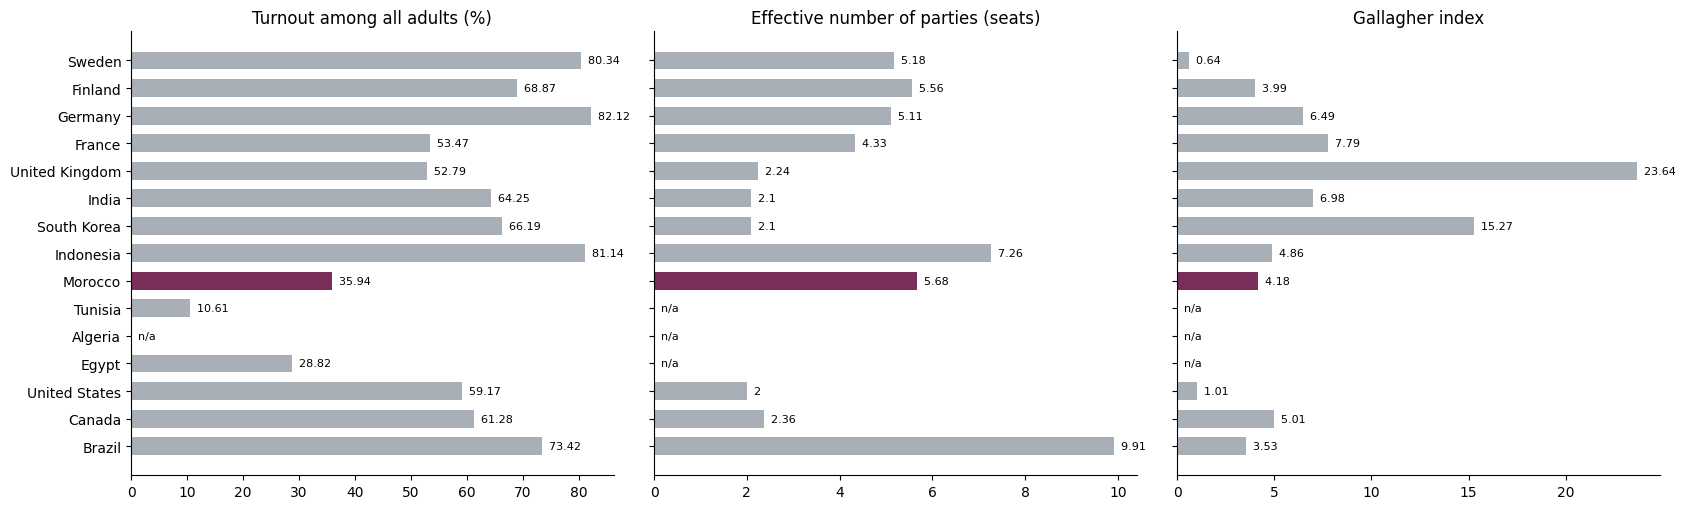

election            regime  democracy_score  turnout_registered  turnout_adults  enp_seats  gallagher  registration_gap
region                  country                                                                                                                               
Scandinavia and Nordics Sweden             2022    Full democracy             9.39               84.21           80.34       5.18       0.64               3.9
                        Finland            2023    Full democracy             9.30               68.50           68.87       5.56       3.99              -0.4
Western Europe          Germany            2025    Full democracy             8.73               82.54           82.12       5.11       6.49               0.4
                        France             2024  Flawed democracy             7.99               66.63           53.47       4.33       7.79              13.2
                        United Kingdom     2024    Full democracy             8.34               59.76           52.79       2.24      23.64               7.0
Asia                    India              2024  Flawed democracy             7.29               65.79           64.25       2.10       6.98               1.5
                        South Korea        2024  Flawed democracy             7.75               66.97           66.19       2.10      15.27               0.8
                        Indonesia          2024  Flawed democracy             6.44               81.42           81.14       7.26       4.86               0.3
North Africa            Morocco            2021     Hybrid regime             4.97               50.86           35.94       5.68       4.18              14.9
                        Tunisia         2022-23     Hybrid regime             4.71               11.40           10.61        NaN        NaN               0.8
                        Algeria            2026     Authoritarian             3.55               21.24             NaN        NaN        NaN               NaN
                        Egypt              2020     Authoritarian             2.79               29.07           28.82        NaN        NaN               0.2
Americas                United States      2024  Flawed democracy             7.85               64.47           59.17       2.00       1.01               5.3
                        Canada             2025    Full democracy             8.69               68.70           61.28       2.36       5.01               7.4
                        Brazil             2022  Flawed democracy             6.49               79.20           73.42       9.91       3.53               5.8

In [25]:
BENCHMARK = pd.DataFrame([
 # region, country, election, regime (EIU), democracy score, turnout registered %, turnout adults %, ENP seats, Gallagher index
 ("Scandinavia and Nordics", "Sweden", "2022", "Full democracy", 9.39, 84.21, 80.34, 5.18, 0.64),
 ("Scandinavia and Nordics", "Finland", "2023", "Full democracy", 9.30, 68.50, 68.87, 5.56, 3.99),
 ("Western Europe", "Germany", "2025", "Full democracy", 8.73, 82.54, 82.12, 5.11, 6.49),
 ("Western Europe", "France", "2024", "Flawed democracy", 7.99, 66.63, 53.47, 4.33, 7.79),
 ("Western Europe", "United Kingdom", "2024", "Full democracy", 8.34, 59.76, 52.79, 2.24, 23.64),
 ("Asia", "India", "2024", "Flawed democracy", 7.29, 65.79, 64.25, 2.10, 6.98),
 ("Asia", "South Korea", "2024", "Flawed democracy", 7.75, 66.97, 66.19, 2.10, 15.27),
 ("Asia", "Indonesia", "2024", "Flawed democracy", 6.44, 81.42, 81.14, 7.26, 4.86),
 ("North Africa", "Morocco", "2021", "Hybrid regime", 4.97, 50.86, 35.94, 5.68, 4.18),
 ("North Africa", "Tunisia", "2022-23", "Hybrid regime", 4.71, 11.40, 10.61, np.nan, np.nan),
 ("North Africa", "Algeria", "2026", "Authoritarian", 3.55, 21.24, np.nan, np.nan, np.nan),
 ("North Africa", "Egypt", "2020", "Authoritarian", 2.79, 29.07, 28.82, np.nan, np.nan),
 ("Americas", "United States", "2024", "Flawed democracy", 7.85, 64.47, 59.17, 2.00, 1.01),
 ("Americas", "Canada", "2025", "Full democracy", 8.69, 68.70, 61.28, 2.36, 5.01),
 ("Americas", "Brazil", "2022", "Flawed democracy", 6.49, 79.20, 73.42, 9.91, 3.53),
], columns=["region", "country", "election", "regime", "democracy_score", "turnout_registered", "turnout_adults", "enp_seats", "gallagher"])
BENCHMARK["registration_gap"] = (BENCHMARK.turnout_registered - BENCHMARK.turnout_adults).round(1)

# How the toolkit's own Morocco figures compare with the external sources (2021)
_k, _c = KPI_NATIONAL.loc["2021"], CENSUS_SUMMARY["2021"]
print("Morocco 2021, toolkit vs external sources:")
print(f"  turnout of registered voters  {_k.turnout_registered:.1%}  vs  50.9% (IDEA)")
print(f"  turnout among adults          {_c['real_turnout_national']:.1%}  vs  35.9% (IDEA; the toolkit divides by the 2014 adult population)")
print(f"  effective parties (seats)     {_k.ENP_seats:.2f}   vs  5.68 (Gallagher; the toolkit counts local seats only)")
print(f"  Gallagher index               {_k.gallagher:.2f}   vs  4.18 (Gallagher; same reason)")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
b = BENCHMARK.iloc[::-1]
for ax, (col, title) in zip(axes, [("turnout_adults", "Turnout among all adults (%)"), ("enp_seats", "Effective number of parties (seats)"), ("gallagher", "Gallagher index")]):
    ax.barh(b.country, b[col], color=["#7A2E5A" if c == "Morocco" else "#A9AFB6" for c in b.country], height=.65)
    for yy, v in enumerate(b[col]): ax.text(0 if pd.isna(v) else v, yy, "  n/a" if pd.isna(v) else f"  {v:g}", va="center", fontsize=8)
    ax.set_title(title); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout(); plt.savefig("fig_benchmark.png", dpi=150); plt.show()
BENCHMARK.set_index(["region", "country"])


## 8 · Export everything to one Excel file

In [26]:
with pd.ExcelWriter(OUTPUT_XLSX) as xw:
    pd.DataFrame({"note": ["Sources: TAFRA results 2002-2021, HCP RGPH 2004 and 2014. 2002: nine parties only, seats over-allocated to them",
                           "Constituency/province correlations do not describe individuals (ecological fallacy)"]}).to_excel(xw, sheet_name="README", index=False)
    RULES.to_excel(xw, sheet_name="Law_rules")
    KPI_NATIONAL.to_excel(xw, sheet_name="KPI_national")
    for y in CONST:
        ENG[y].to_excel(xw, sheet_name=f"Engineering_{y}")
        CONST[y].to_excel(xw, sheet_name=f"Constituencies_{y}", index=False)
        CENSUS_MERGED[y].to_excel(xw, sheet_name=f"Census_merge_{y}", index=False)
        PROFILE[y].to_excel(xw, sheet_name=f"Vote_profile_{y}")
    FORENSICS.to_excel(xw, sheet_name="Forensics")
    pd.DataFrame(CENSUS_SUMMARY).T.to_excel(xw, sheet_name="Census_KPIs")
    SCORECARD.to_excel(xw, sheet_name="Scorecard", index=False)
    POWER.to_excel(xw, sheet_name="Power_module", index=False)
    for y in SAME_VOTES: SAME_VOTES[y].to_excel(xw, sheet_name=f"Same_votes_{y}")
    AFTER_VOTE.to_excel(xw, sheet_name="After_the_vote")
    KEY_MINISTRIES.to_excel(xw, sheet_name="Key_ministries", index=False)
    CHAIN.to_excel(xw, sheet_name="Chain_transmission", index=False)
    PORTFOLIOS.to_excel(xw, sheet_name="Portfolios", index=False)
    GAMSON.to_excel(xw, sheet_name="Gamson_weighted")
    EXTRA.to_excel(xw, sheet_name="Power_extra")
    for y in YEARS: PROVINCE[y].to_excel(xw, sheet_name=f"Province_{y}")
    for k, fl in FLOWS.items(): fl.to_excel(xw, sheet_name=f"Seat_flows_{k}", index=False)
    pd.concat(PARTY_VIEW, names=["party", "year"]).to_excel(xw, sheet_name="Party_view")
    WHATIF.to_excel(xw, sheet_name="Turnout_what_if", index=False)
    BENCHMARK.to_excel(xw, sheet_name="Benchmark", index=False)
print("Saved:", OUTPUT_XLSX)

Saved: kpi_elections_maroc_v3.xlsx
